# Testing differential gene module expression between groups of cells

In [1]:
library(ggplot2)
library(ggrepel)
library(plyr)
library(dplyr)
library(Seurat)
library(tidyr) 
library(DescTools)
library(parallel)
library(pheatmap)
library(ggbeeswarm)
library(forcats)
library(parameters)


source("../sc_analysis_palettes_and_helpers.r")

setwd("/local/users/nfresma/R_out/all_clones/")

dat_name <- "allClones_new"

Warning message:
“package ‘plyr’ was built under R version 4.0.5”

Attaching package: ‘dplyr’


The following objects are masked from ‘package:plyr’:

    arrange, count, desc, failwith, id, mutate, rename, summarise,
    summarize


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Attaching SeuratObject

Warning message:
“package ‘tidyr’ was built under R version 4.0.5”
Warning message:
“package ‘forcats’ was built under R version 4.0.3”


## Load NB cell data with modules scores and clone info

In [37]:
# Load Seurat metadata with high-resolution clone assignments and module scores
dat <- readRDS(paste0('/local/users/nfresma/repos/neuroblastoma_plasticity/lineage_aware_expression_analysis/data/seur_obj_NBcells_with_clones_and_scores_DR_NB_modules_',dat_name,'.rds'))


In [38]:
# Load final module table
modules_pan <- read.delim('/local/users/nfresma/repos/neuroblastoma_plasticity/gene_modules/final_gene_modules_list.csv', sep = ';', stringsAsFactors = F, header = T)

# Re-format into list
modules_pan <- as.list(modules_pan)

# Double-check that common gene names contain correct set of special characters
modules_pan <- lapply(modules_pan, function(x) gsub("si\\.","si:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("zgc\\.","zgc:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("mt\\.","mt-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("dkey\\.","dkey-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("h211\\.","h211-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("ch73\\.","ch73-",x))

# Remove empty entries
modules_pan <- lapply(modules_pan, function(x) {
  # Remove NA and empty string "" entries
  x[!(is.na(x) | x == "")]
})

# Remove modules that are too short
modules_pan <- modules_pan[lengths(modules_pan) > 5]

## Plot clone assignments and module scores per fish

In the following, we prepare the data and then generate plots for NB cells from each fish separately.  
First, metadata columns are prepared for plotting.  
Then the following is done for all fish separately:  
- Subsetting of Seurat object for cells from fish; processing and clustering of the subset of cells.
- UMAPs showing cells colored by seurat clusters, clone IDs and other metadata information.
- Barplots showing the fraction of cells from each clone assigned to each seurat cluster.
- Boxplots of module expression scores in cells grouped by clones. Significance of module expression differences between clones is calculated and included in the plot.

In [39]:
# Add a few more info columns to metadata in preparation

# Unambiguous tumor identifier
dat@meta.data$sample_tumour <- paste0(dat@meta.data$dataset,'_',dat@meta.data$fish_id, '_', dat@meta.data$tumor_id)

# Unambiguous fish identifier
dat@meta.data$sample_fish <- paste0(dat@meta.data$dataset,'_',dat@meta.data$fish_id)

# Unambiguous tumor identifier with location info
dat@meta.data$sample_tumour_loc <- paste0(dat@meta.data$sample_tumour ,'_',dat@meta.data$location)

# Unambiguous sub-tumor and clone identifier
dat@meta.data$location_clones <- 'none'
dat@meta.data$location_clones <- paste0(dat@meta.data$fish_clone,'_tum_',dat@meta.data$tumor_id)

# Unambiguous fish and clone identifier
dat@meta.data$fish_loc_clone <- paste0(dat@meta.data$fish_clone ,'_loc_',dat@meta.data$location)

## Add a shortened cloneID
dat@meta.data$cloneID[!is.na(dat@meta.data$fish_clone)] <- sub(".*clone_", "", dat$fish_clone[!is.na(dat@meta.data$fish_clone)])
dat@meta.data$cloneID <- trimws(dat@meta.data$cloneID)
dat@meta.data$cloneID <- as.character(as.factor(dat@meta.data$cloneID))

dat@meta.data$sample_fish <- as.factor(dat@meta.data$sample_fish)

In [70]:
# Add a numeric value for the clones that ranges from 1-n per fish, where n is the total number of clones
dat@meta.data$Barcode <- rownames(dat@meta.data)

dat@meta.data$cloneID_numeric <- NULL
dat@meta.data$cloneID <- as.factor(as.character(dat@meta.data$cloneID))

metadat <- dat@meta.data %>%
          group_by(sample_fish) %>%
          mutate(
            cloneID_numeric = ifelse(
              is.na(cloneID), 
              NA, 
              as.integer(factor(cloneID, levels = unique(cloneID[!is.na(cloneID)])))
            )
          ) %>%
          ungroup()

metadat$cloneID <- as.character(metadat$cloneID)
metadat <- as.data.frame(metadat)
rownames(metadat) <- metadat$Barcode

#metadat <- metadat[rownames(dat@meta.data),]
table(rownames(metadat) == rownames(dat@meta.data))



 TRUE 
62886 

In [76]:
# If the above rownames match (100% TRUE), add extended metadata to Seurat object
dat@meta.data <- metadat

In [78]:
# Remove generic parts of the clone naming string
dat@meta.data$dataset_clone <- gsub('_fish','',dat@meta.data$fish_clone)

# Function to remove 'clone' and the number following it
remove_clone <- function(input_string) {
  # Use gsub to remove 'clone_' and the number(s) before the next underscore
  gsub("_clone_[0-9]+_", "_", input_string)
}

# Apply the function to each string
dat@meta.data$dataset_clone <- sapply(dat@meta.data$dataset_clone, remove_clone)

In [81]:
# Remove clonal label for clones that have fewer than 10 cells

dat@meta.data$sample_clone <- paste0(dat@meta.data$sample_all, '_', dat@meta.data$fish_clone)
clone_freqs <- as.data.frame(table(dat@meta.data$sample_clone))
clone_freqs <- clone_freqs[clone_freqs$Freq < 10,]

dat@meta.data$cloneID[dat@meta.data$sample_clone %in% clone_freqs$Var1] <- NA
dat@meta.data$fish_clone[dat@meta.data$sample_clone %in% clone_freqs$Var1] <- NA
dat@meta.data$sample_clone[dat@meta.data$sample_clone %in% clone_freqs$Var1] <- NA
dat@meta.data$cloneID_numeric[dat@meta.data$sample_clone %in% clone_freqs$Var1] <- NA


In [44]:
b1 <- 1
b2 <- length(modules_pan)

# Select score_type to look at

score_type <- 'auc'

# Select modules to plot for all clones in the loop below
module_metnames <- names(modules_pan)

set_all <- module_metnames[1:length(module_metnames)]
set_name <- 'set_all'

# Add ID to module number depending on assay used
if(score_type == 'tirosh'){
    set_all <- paste0('tirosh_',set_all)

}else if(score_type == 'barkley'){
    set_all <- paste0('barkley_',set_all)

}else if(score_type == 'auc'){
    set_all <- paste0('auc_',set_all)
        
}else if(score_type == 'metafeatures'){
    set_all <- paste0('meta_',set_all)
        
}


In [83]:
i <- 1
# Get the sub data set
    sample_name <- samples_to_plot[i]

    Idents(dat) <- 'sample_fish'

    sub <- subset(dat, idents = sample_name)
    
# Stop, if there is only one clone in the data or if the sample contains less than 25 cells    
    if(length(unique(sub$fish_clone)) == 1 || ncol(sub) < 25){
        next
    }

# Process the sub data set to get clusters and UMAP-coordinates
    print(paste0('Working on dataset: ',sample_name))
    print(paste0('Number of cells: ',ncol(sub)))

    all.genes <- rownames(x = sub)
    sub <- ScaleData(object = sub, features = all.genes)
    sub <- FindVariableFeatures(object = sub,selection.method = 'vst', nfeatures = 1500)

    # PCA
    if(ncol(sub) < 50){
        sub <- RunPCA(object = sub, features = VariableFeatures(object = sub), npcs = 20, verbose = F)
        ndims <- 15
    }else if(ncol(sub) < 120){
        sub <- RunPCA(object = sub, features = VariableFeatures(object = sub), npcs = 30, verbose = F)
        ndims <- 20
    }else{
        sub <- RunPCA(object = sub, features = VariableFeatures(object = sub), npcs = 60, verbose = F)
        ndims <- 25
    }

    # Clustering
    k <- round(max(20,sqrt(ncol(sub)))/4)
    if(k %% 2 == 0) {k <- k+1}
    if(k > 41) {k <- 41}

    sub <- FindNeighbors(object = sub, dims = 1:ndims, k.param = k, verbose = F)
    sub <- FindClusters(object = sub, resolution = 0.4, verbose = F)

    sub <- RunUMAP(sub, reduction = "pca", dims = 1:ndims, n.components = 2, verbose = F)


[1] "Working on dataset: multi_seq_02_3"
[1] "Number of cells: 3624"


Centering and scaling data matrix



[1] "Working on dataset: multi_seq_17_5"
[1] "Number of cells: 1369"


Centering and scaling data matrix



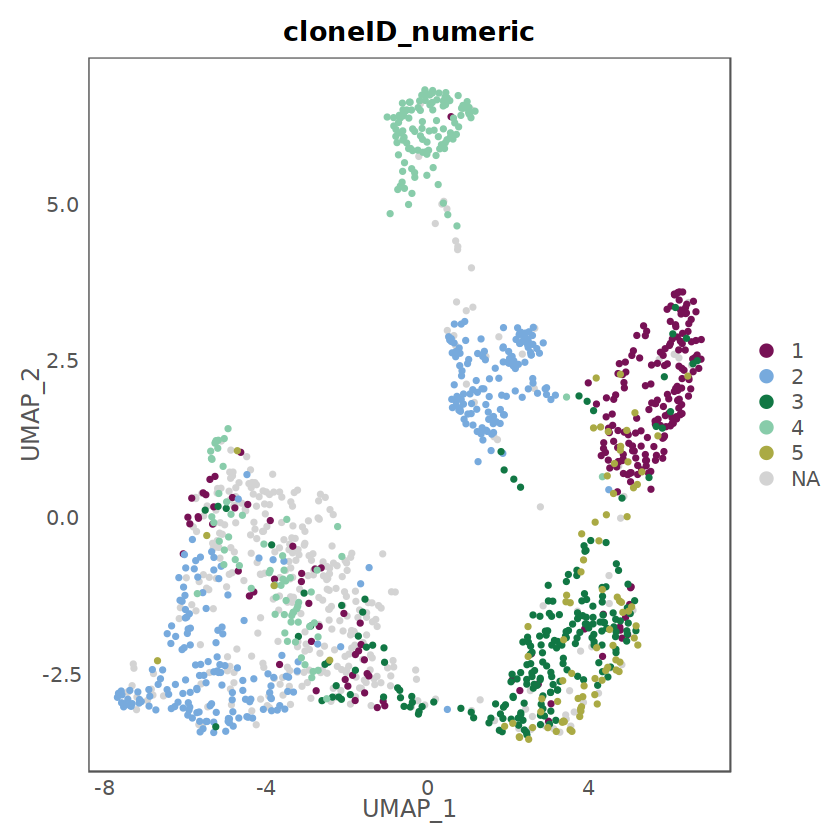

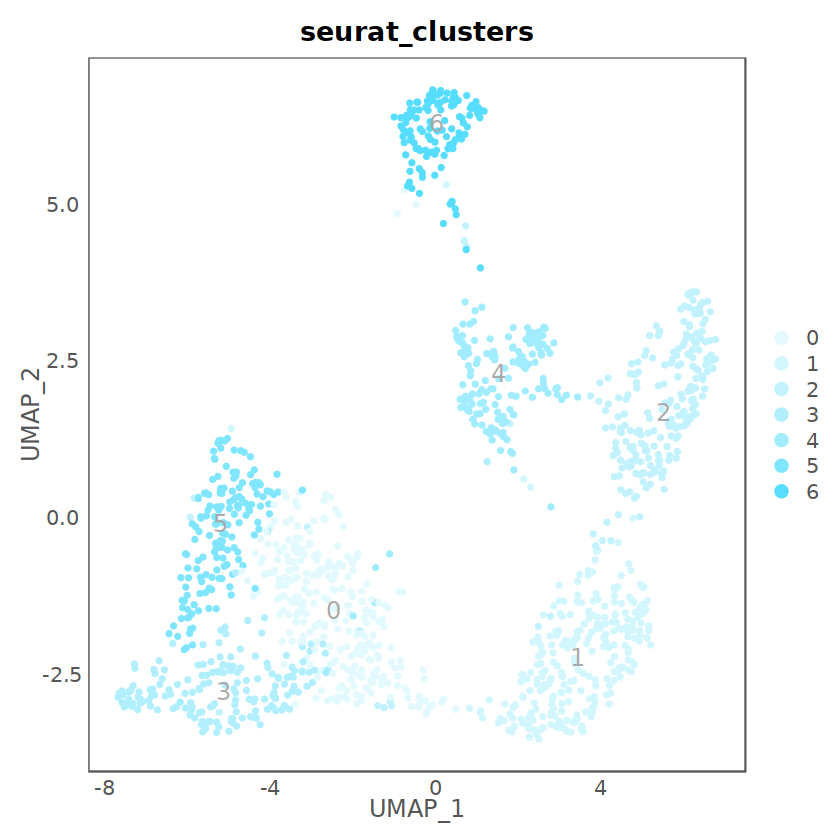

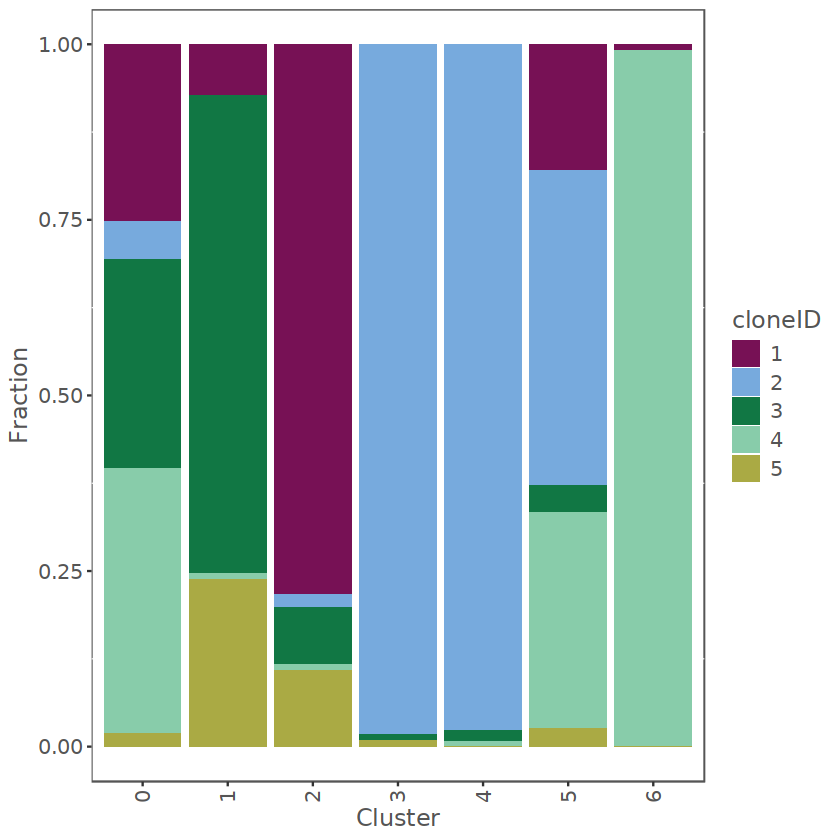

[1] "Plotting module expression boxplots"


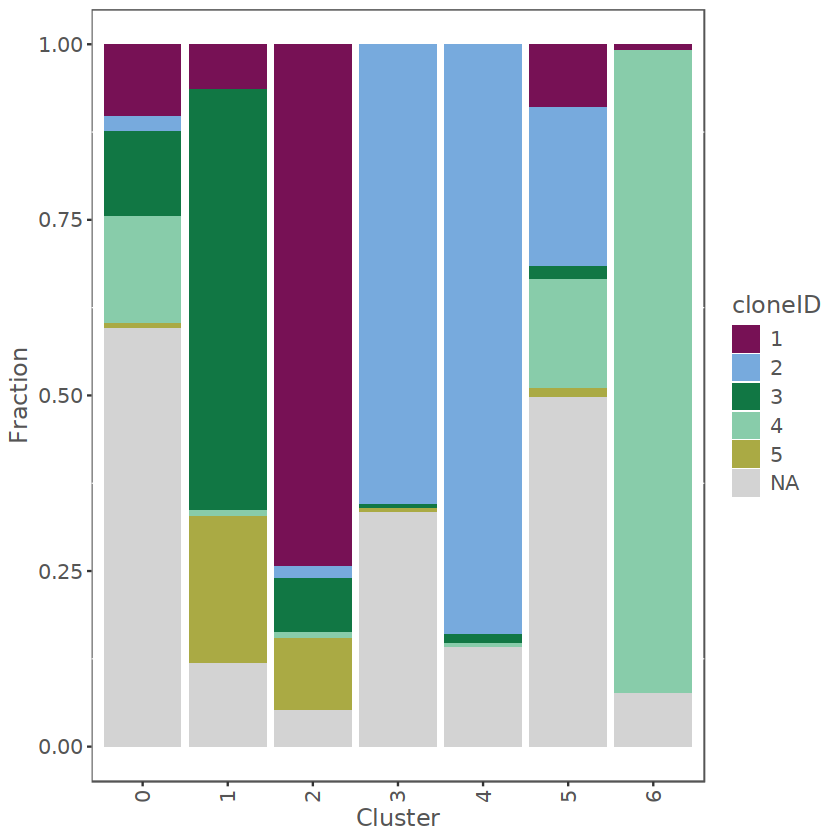

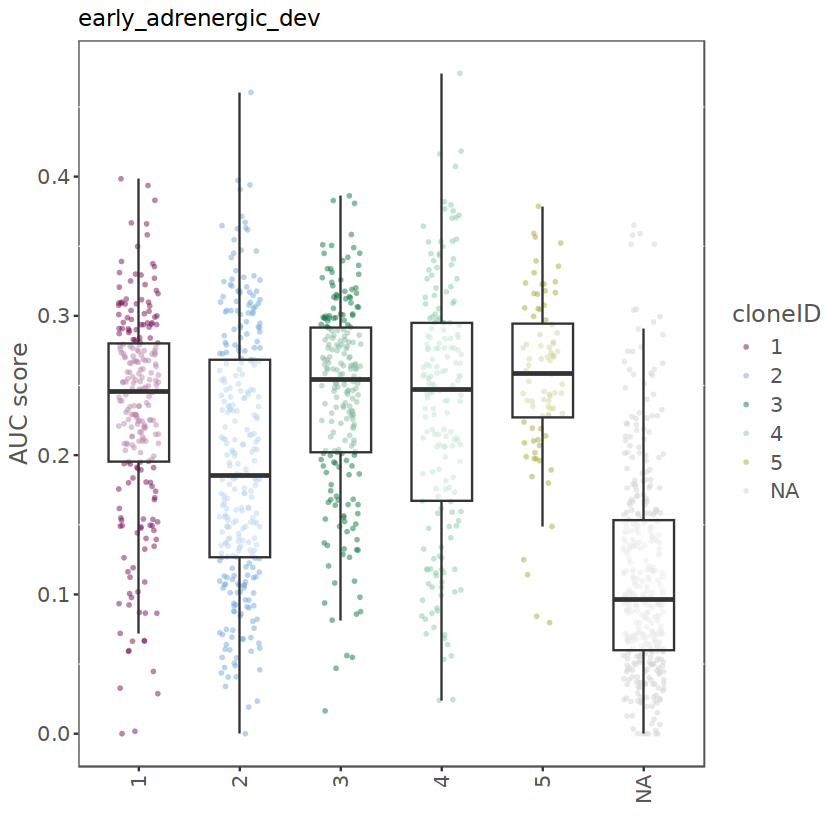

[1] "Working on dataset: multi_seq_17_1"
[1] "Number of cells: 1869"


Centering and scaling data matrix



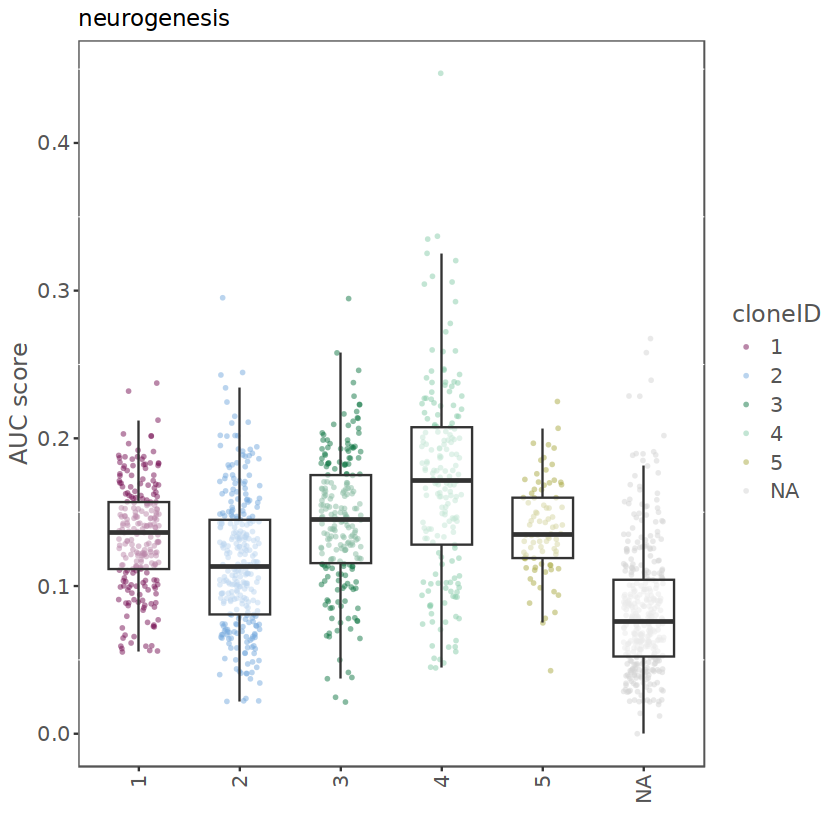

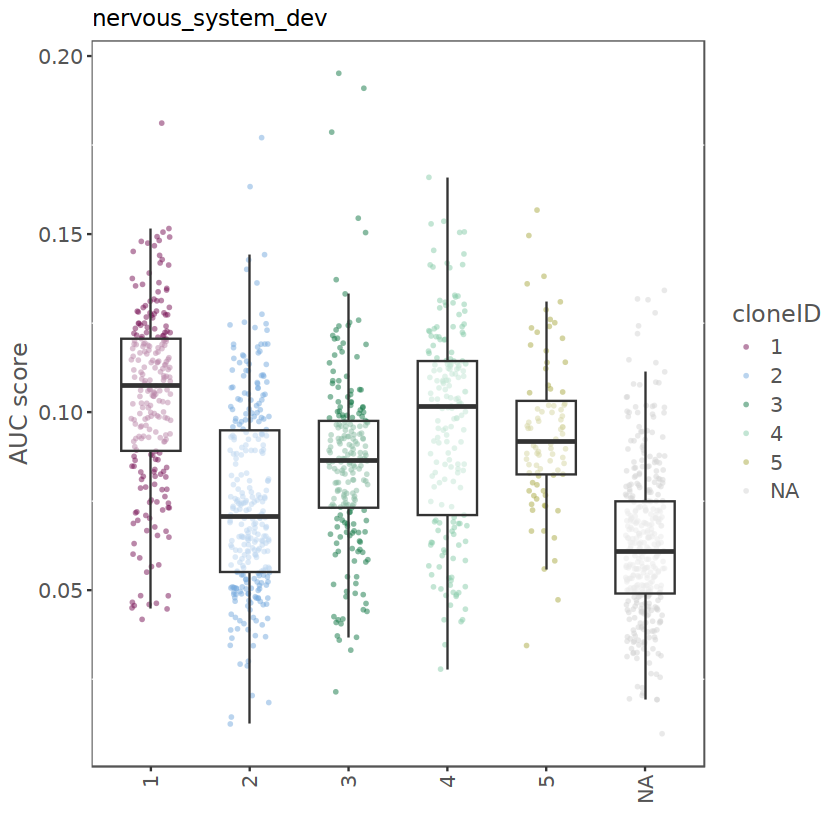

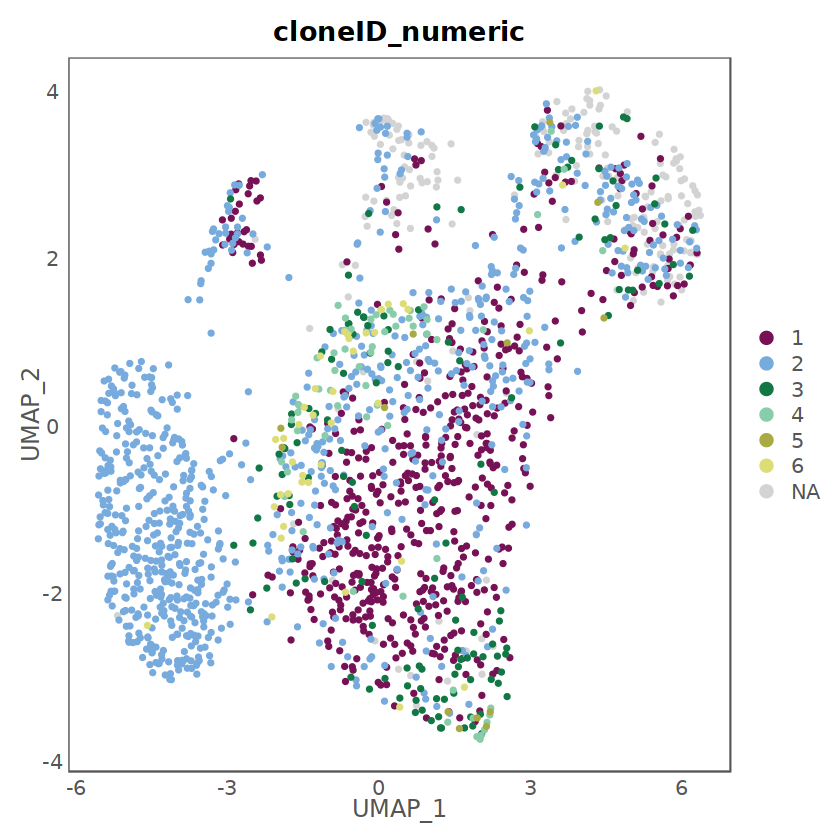

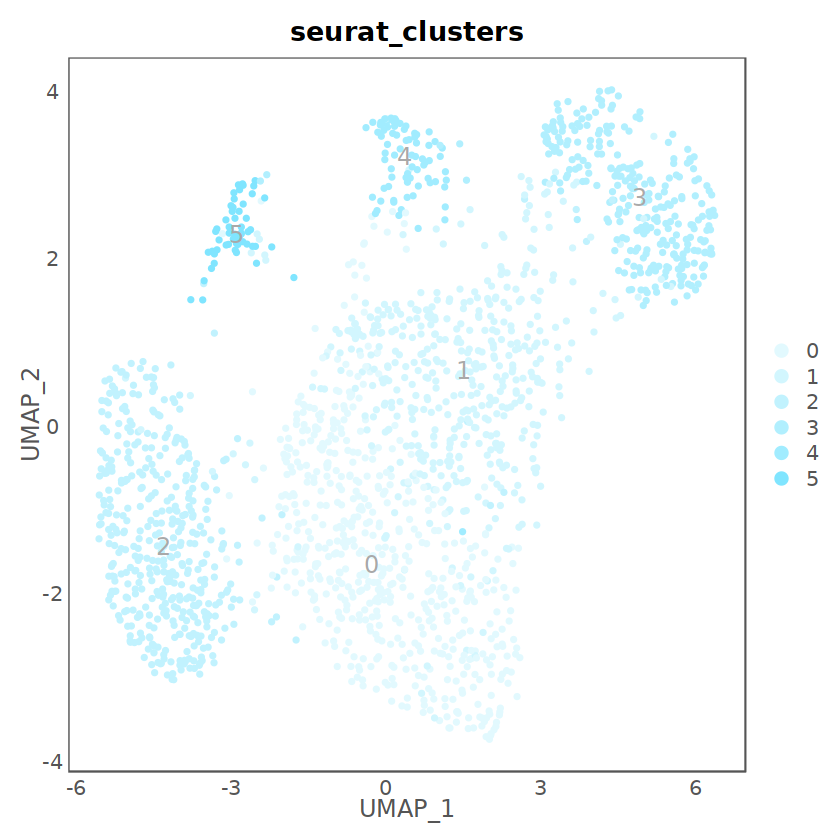

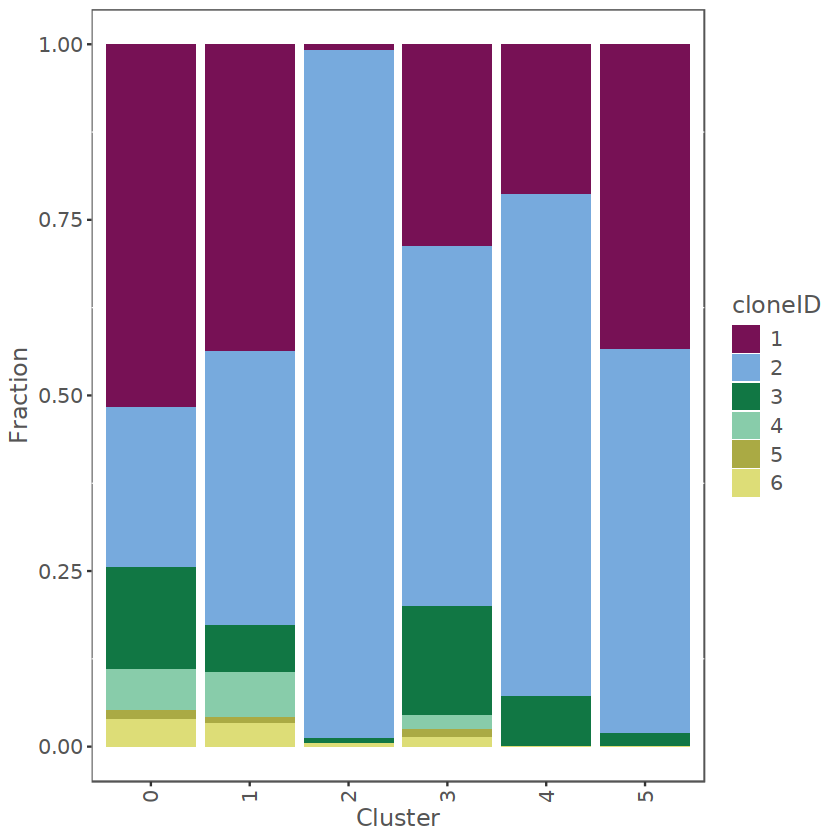

[1] "Plotting module expression boxplots"


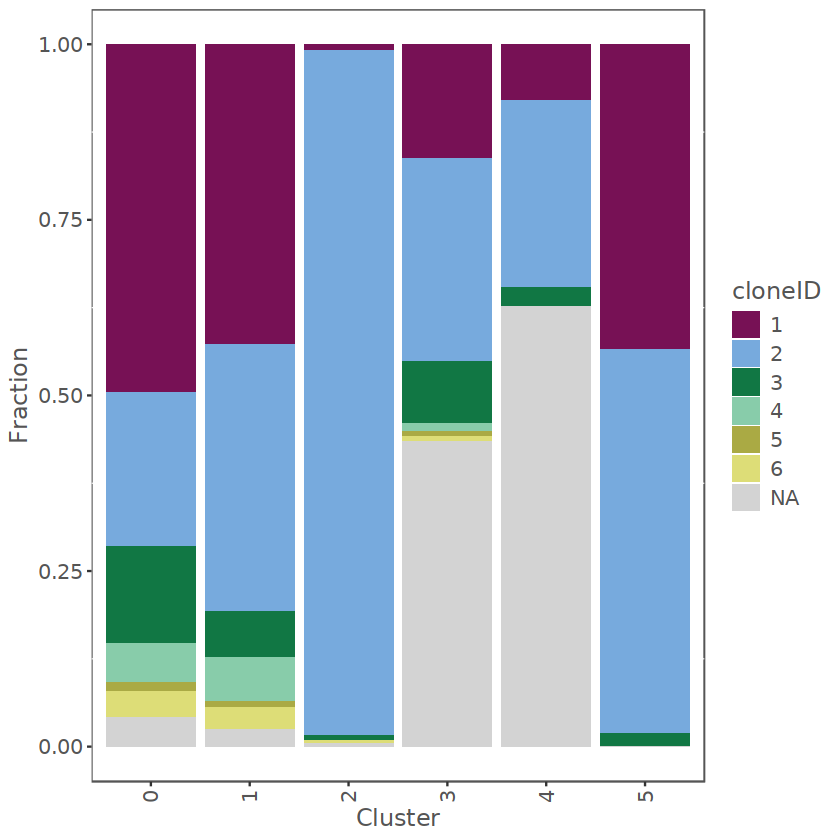

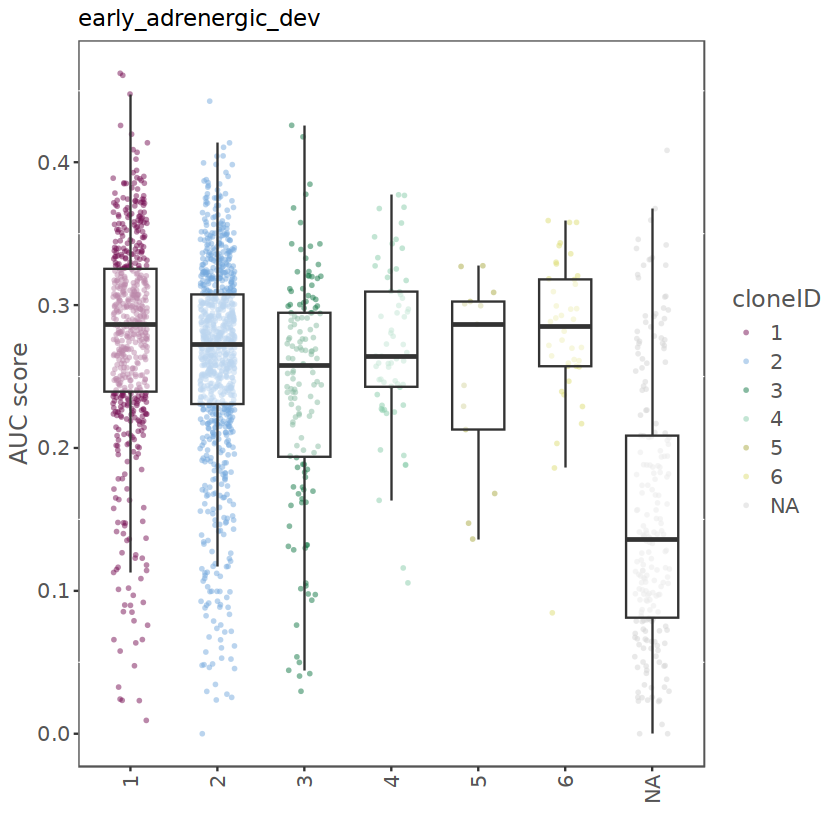

[1] "Working on dataset: multi_seq_17_3"
[1] "Number of cells: 801"


Centering and scaling data matrix



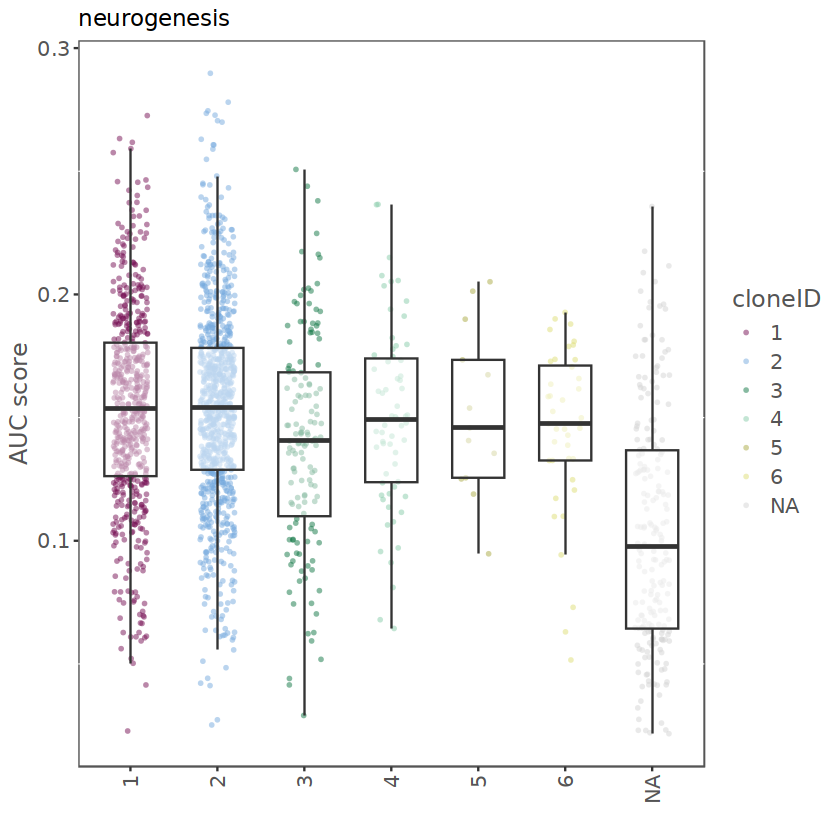

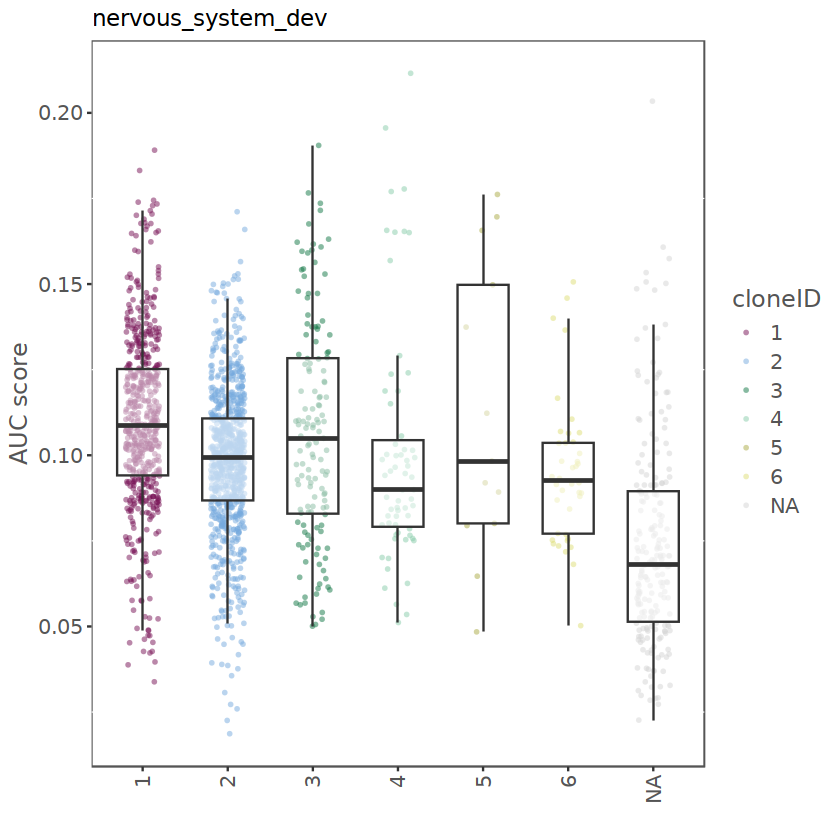

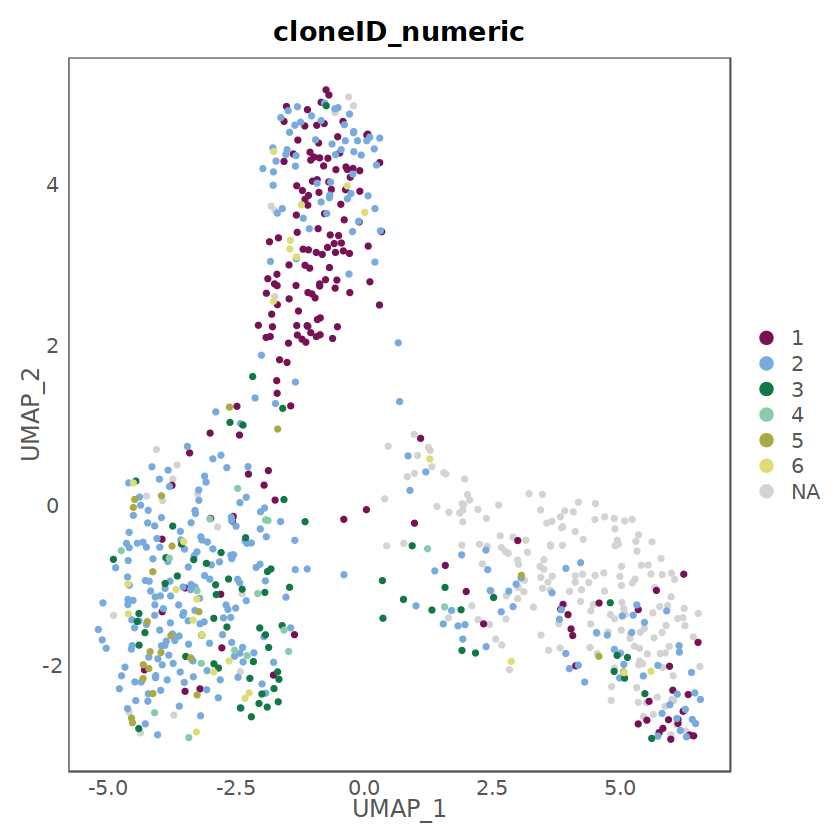

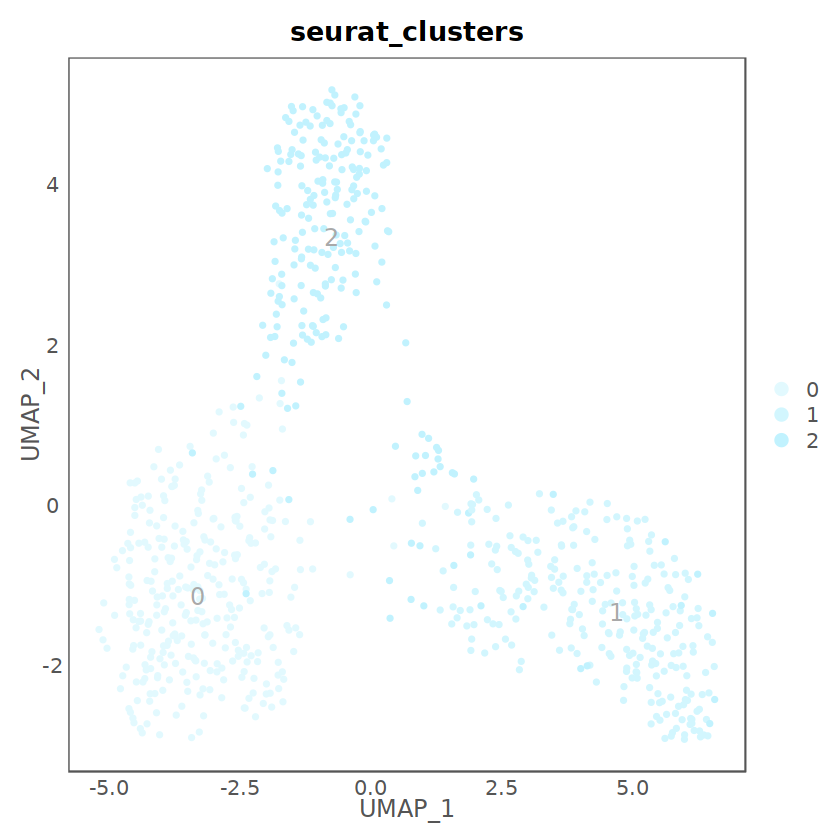

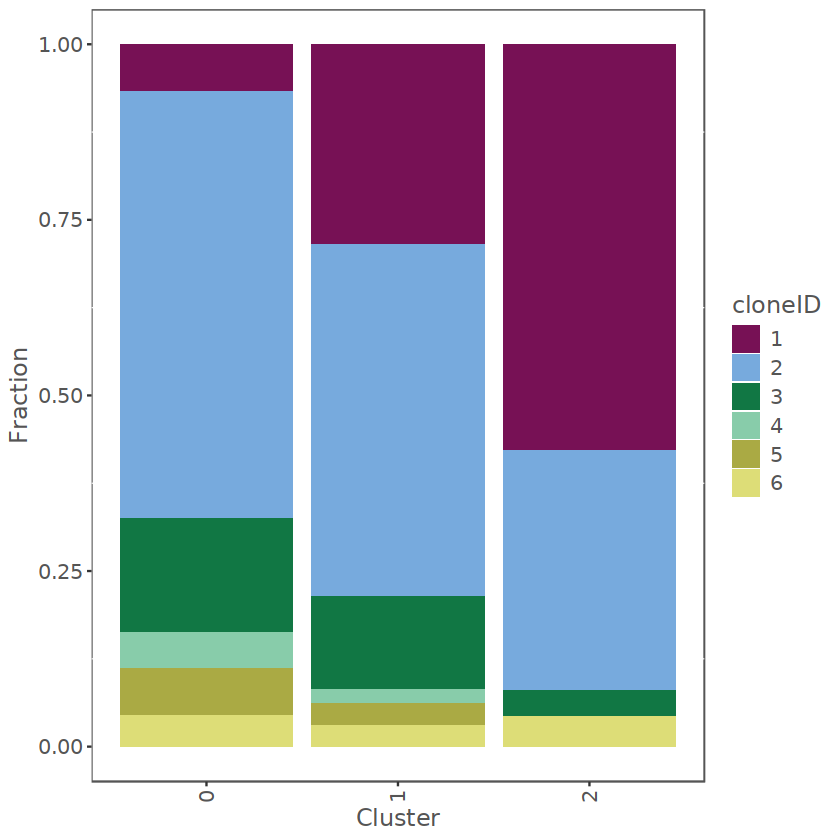

[1] "Plotting module expression boxplots"


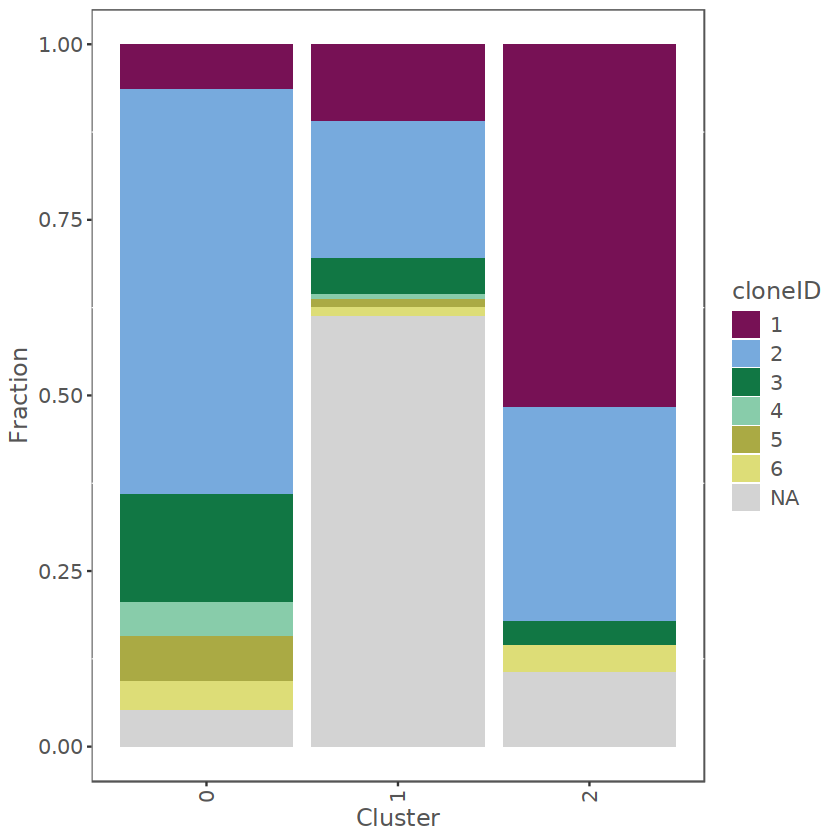

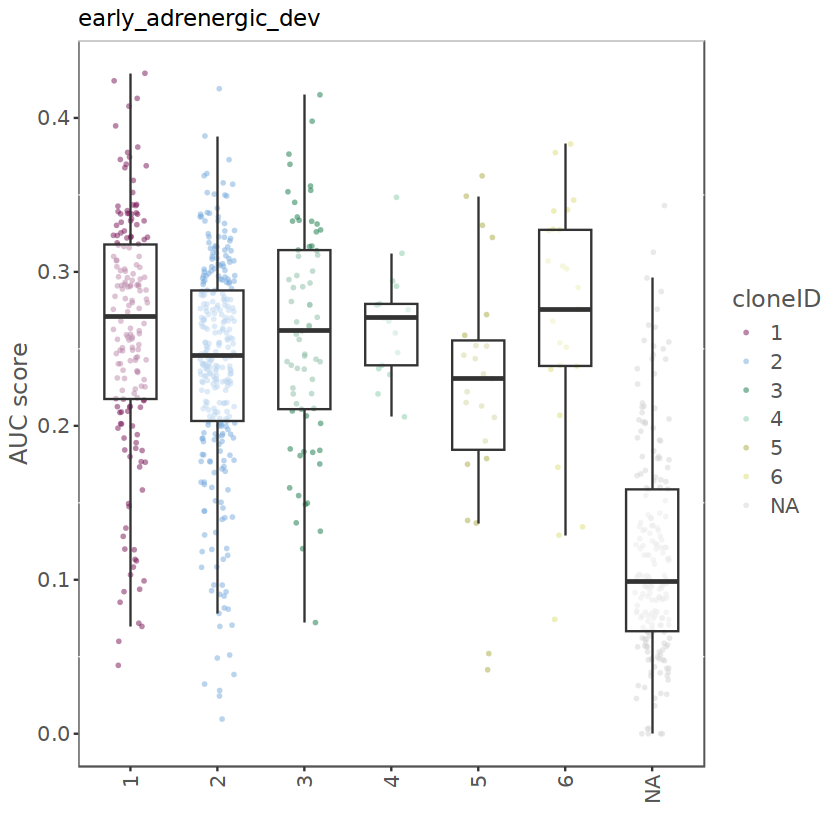

[1] "Working on dataset: multi_seq_17_2"
[1] "Number of cells: 1880"


Centering and scaling data matrix



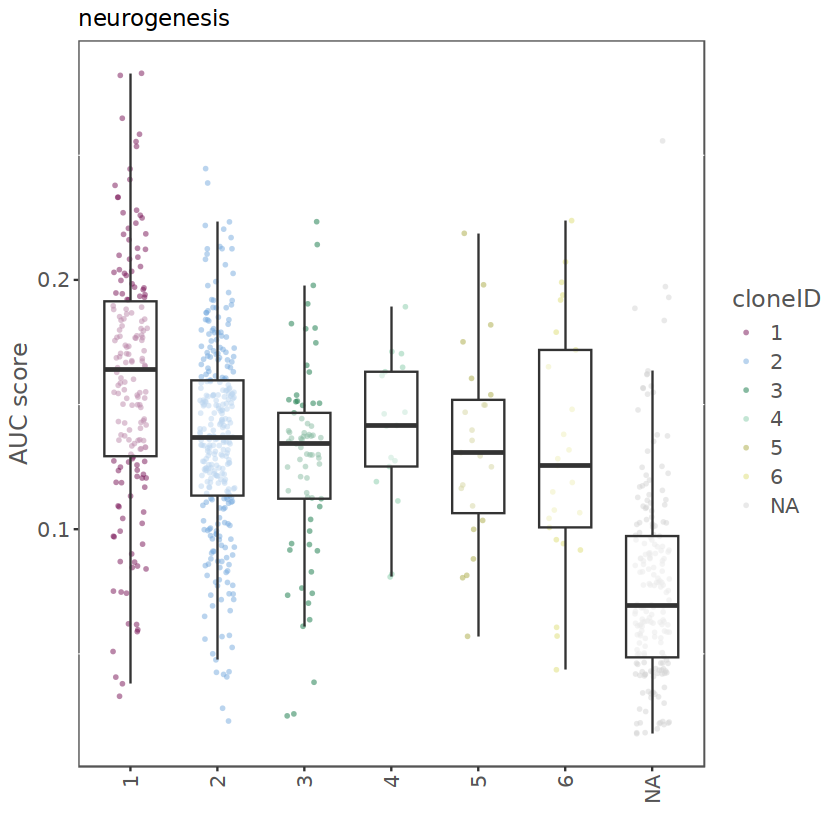

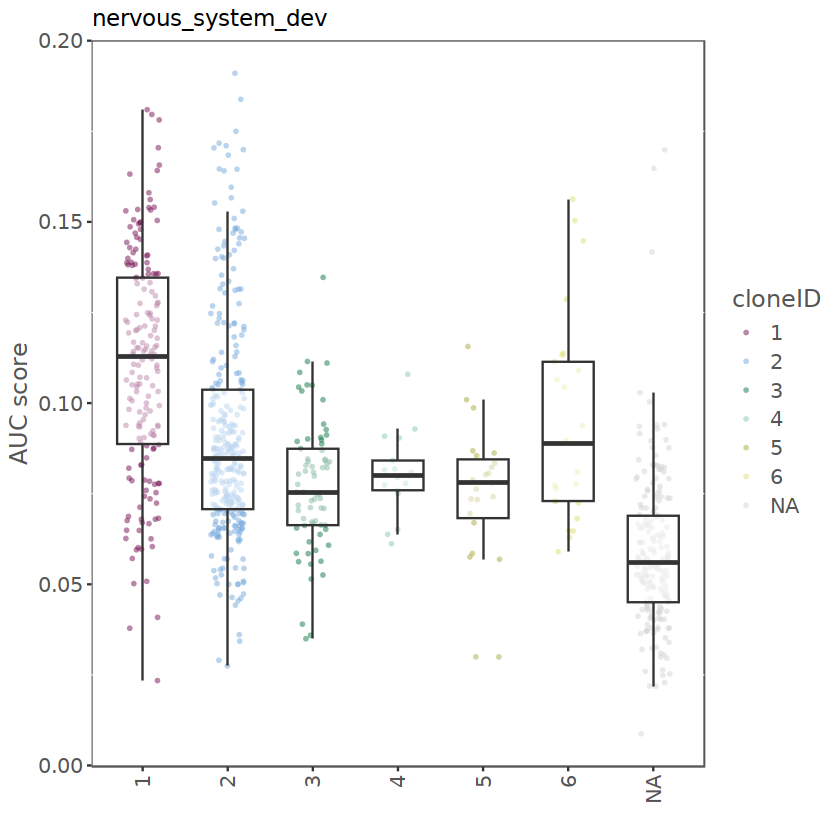

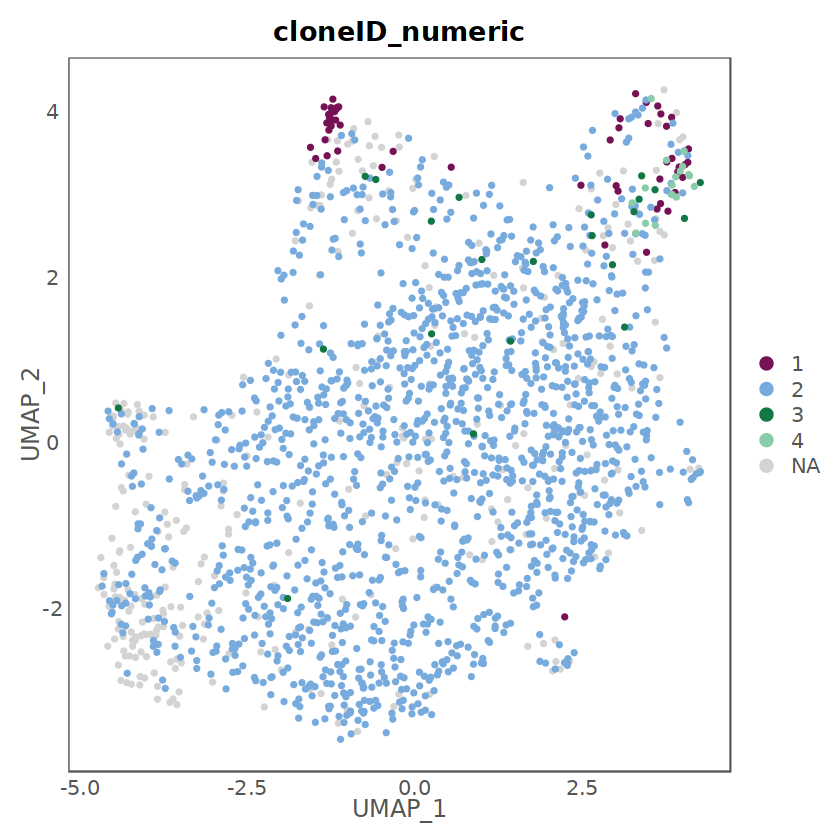

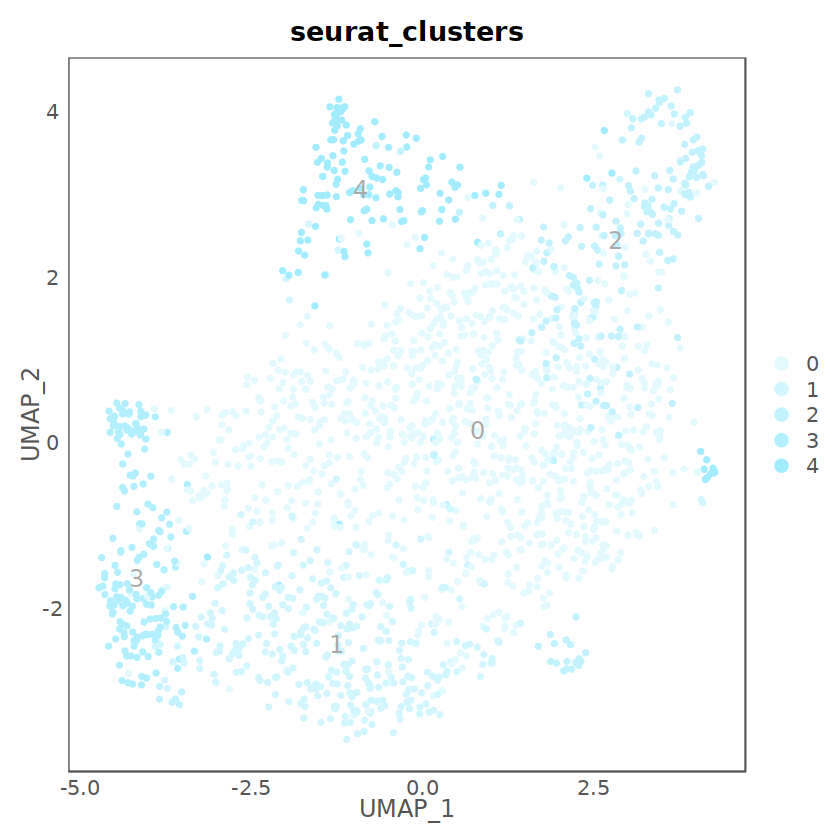

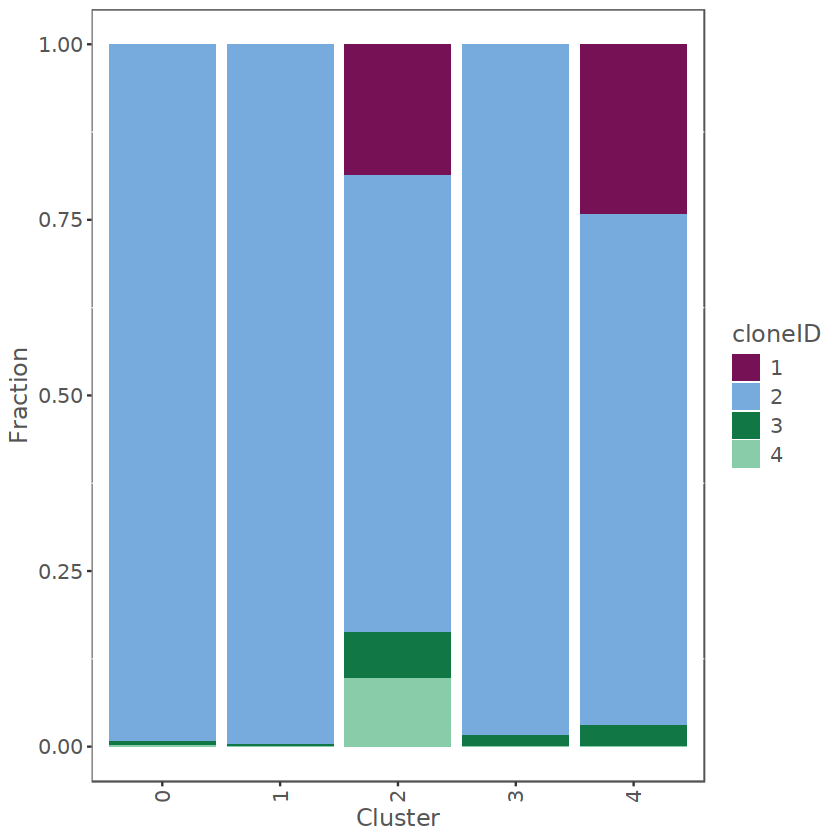

[1] "Plotting module expression boxplots"


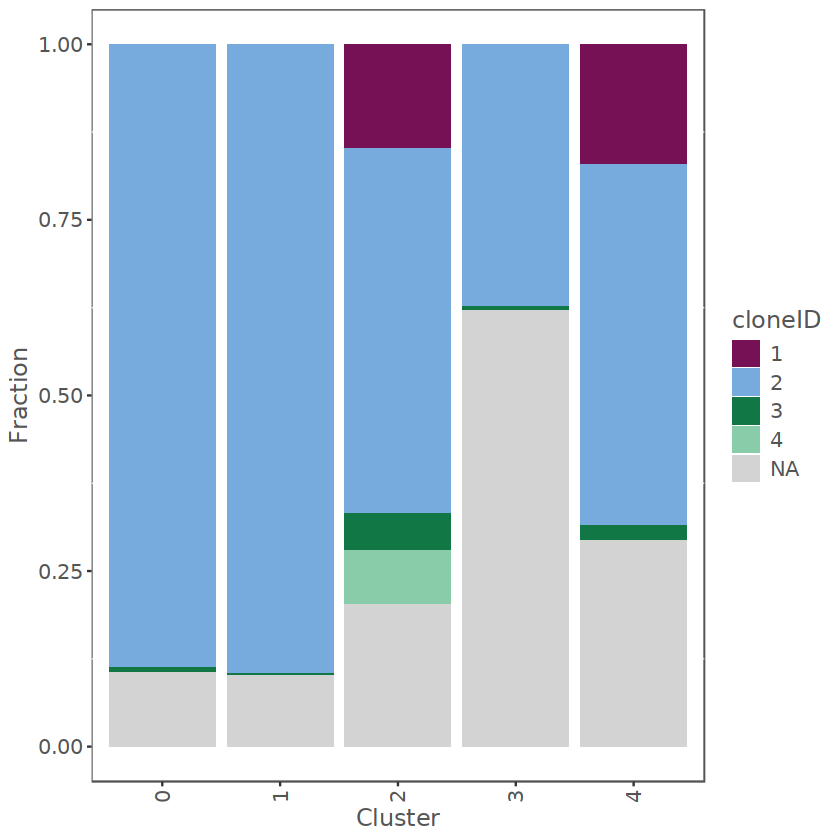

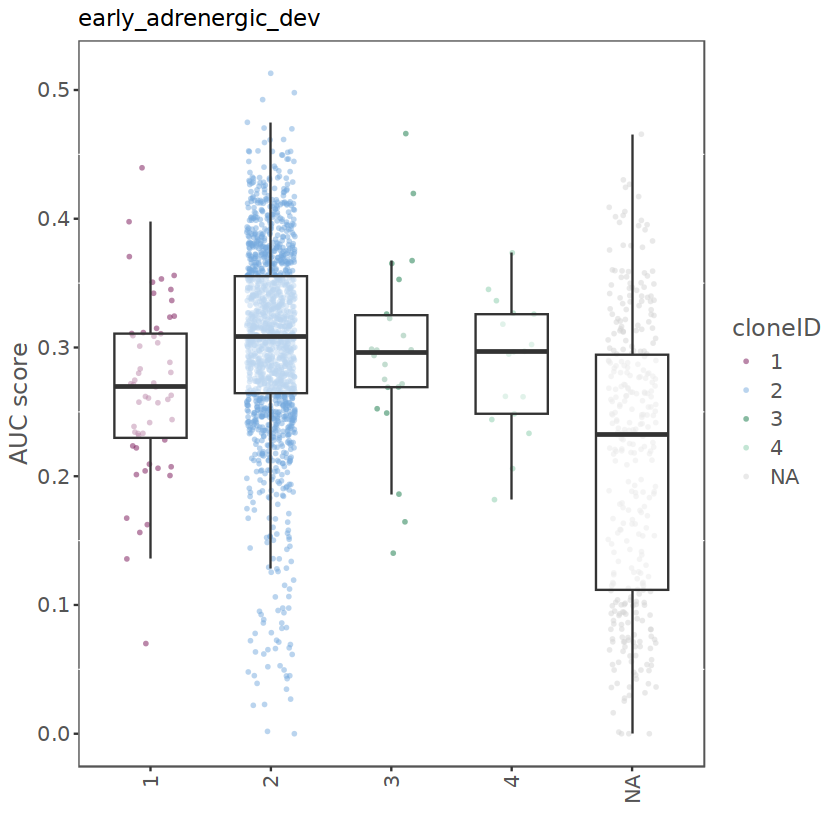

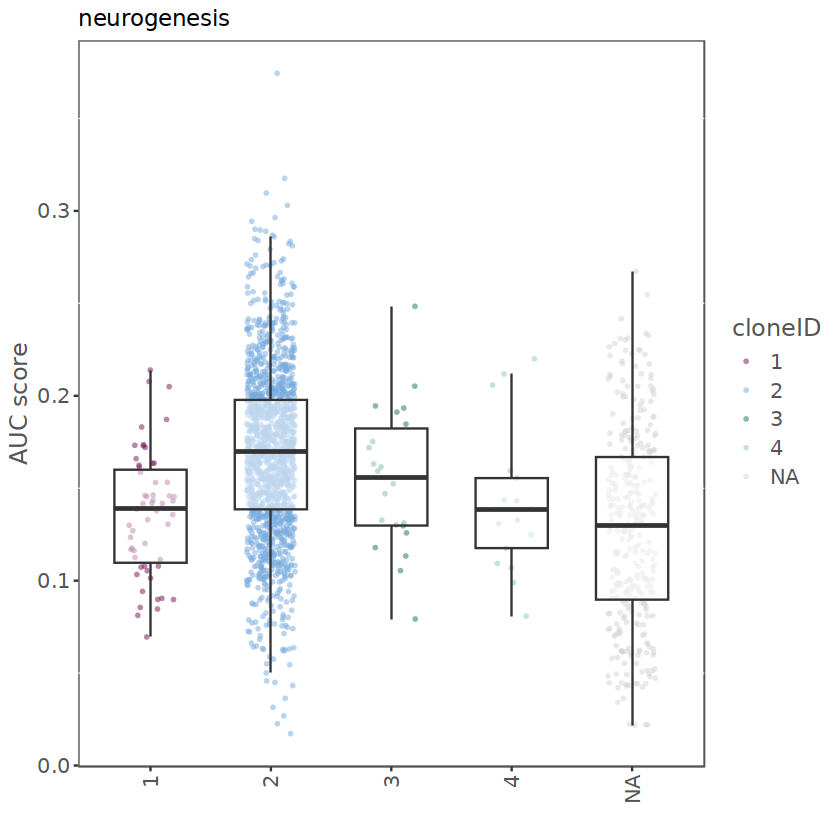

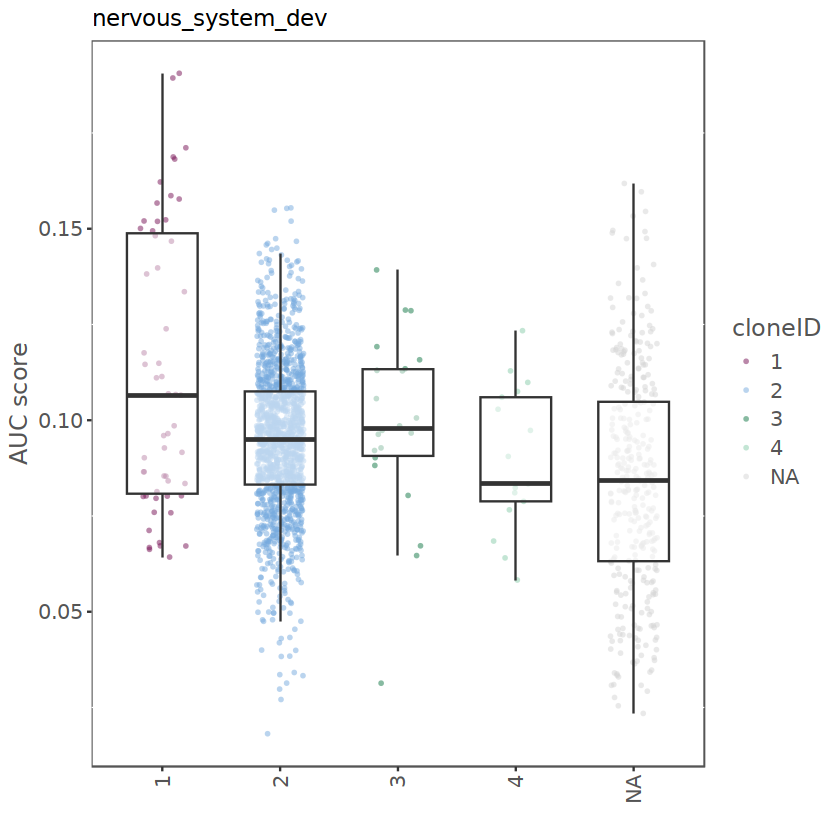

In [86]:
# Per sample_fish
samples_to_plot <- unique(dat@meta.data$sample_fish)

#for(i in rev(1:length(samples_to_plot))){
for(i in rev((length(samples_to_plot)-3):length(samples_to_plot))){

# Get the sub data set
    sample_name <- samples_to_plot[i]

    Idents(dat) <- 'sample_fish'

    sub <- subset(dat, idents = sample_name)
    
# Stop, if there is only one clone in the data or if the sample contains less than 25 cells    
    if(length(unique(sub$fish_clone)) == 1 || ncol(sub) < 25){
        next
    }

# Process the sub data set to get clusters and UMAP-coordinates
    print(paste0('Working on dataset: ',sample_name))
    print(paste0('Number of cells: ',ncol(sub)))

    all.genes <- rownames(x = sub)
    sub <- ScaleData(object = sub, features = all.genes)
    sub <- FindVariableFeatures(object = sub,selection.method = 'vst', nfeatures = 1500)

    # PCA
    if(ncol(sub) < 50){
        sub <- RunPCA(object = sub, features = VariableFeatures(object = sub), npcs = 20, verbose = F)
        ndims <- 15
    }else if(ncol(sub) < 120){
        sub <- RunPCA(object = sub, features = VariableFeatures(object = sub), npcs = 30, verbose = F)
        ndims <- 20
    }else{
        sub <- RunPCA(object = sub, features = VariableFeatures(object = sub), npcs = 60, verbose = F)
        ndims <- 25
    }

    # Clustering
    k <- round(max(20,sqrt(ncol(sub)))/4)
    if(k %% 2 == 0) {k <- k+1}
    if(k > 41) {k <- 41}

    sub <- FindNeighbors(object = sub, dims = 1:ndims, k.param = k, verbose = F)
    sub <- FindClusters(object = sub, resolution = 0.4, verbose = F)

    sub <- RunUMAP(sub, reduction = "pca", dims = 1:ndims, n.components = 2, verbose = F)

    
# Plot UMAPS

    print(
        DimPlot(object = sub, reduction = 'umap', pt.size = 1, group.by = "cloneID_numeric", dims = c(1,2), cols = tol21rainbow[c(1,6,10,12,14,15,16,18,20,22,24,26,28,29,30,31,32,33,21,23,3,4,9,12,2)], order = T, na.value="light grey") +
                 NoAxes() +
                 mytheme_angledYtitle
         )
    
    ploto <- DimPlot(object = sub, reduction = 'umap', pt.size = 1, group.by = "cloneID_numeric", dims = c(1,2), cols = tol21rainbow[c(1,6,10,12,14,15,16,18,20,22,24,26,28,29,30,31,32,33,21,23,3,4,9,12,2)], order = T, na.value="light grey") +
                 NoAxes() +
                 mytheme_angledYtitle

    #ggsave(plot = ploto, filename = paste0("pics/EntireTum_UMAP_tumour_sample_fish_",sample_name,"_ncells_",ncol(sub),"_fishCloneIDnumeric.png"), width = 4.1, height = 3.4, dpi = 900)
    rm(ploto)


    ploto <- DimPlot(object = sub, reduction = 'umap', pt.size = 1, group.by = "cloneID", dims = c(1,2), cols = tol21rainbow[c(1,6,10,12,14,15,16,18,20,22,24,26,28,29,30,31,32,33,21,23,3,4,9,12,2)], order = T, na.value="light grey") +
                 NoAxes() +
                 mytheme_angledYtitle
    
    #ggsave(plot = ploto, filename = paste0("pics/EntireTum_UMAP_tumour_sample_fish_",sample_name,"_ncells_",ncol(sub),"_fishCloneID.png"), width = 4.6, height = 3.8, dpi = 500)
    rm(ploto)


    ploto <- DimPlot(object = sub, reduction = 'umap', pt.size = 1, group.by = "tumor_id", dims = c(1,2), cols = tol21rainbow[c(1,6,10,12,14,15,16,18,20,22,24,26,28,29,30,31,32,33,21,23,3,4,9,12,2)], shuffle = T, na.value="light grey") +
                 NoAxes() +
                 mytheme_angledYtitle
    
    #ggsave(plot = ploto, filename = paste0("pics/EntireTum_UMAP_tumour_sample_fish_",sample_name,"_ncells_",ncol(sub),"_tumor.png"), width = 4.2, height = 3.4, dpi = 900)
    rm(ploto)

    ploto <- DimPlot(object = sub, reduction = 'umap', pt.size = 1, group.by = "location", dims = c(1,2), cols = tol21rainbow[c(1,6,10,12,14,15,16,18,20,22,24,26,28,29,30,31,32,33,21,23,3,4,9,12,2)], shuffle = T, na.value="light grey") +
                 NoAxes() +
                 mytheme_angledYtitle
    
    #ggsave(plot = ploto, filename = paste0("pics/EntireTum_UMAP_tumour_sample_fish_",sample_name,"_ncells_",ncol(sub),"_location.png"), width = 7.6, height = 6.5, dpi = 500)
    rm(ploto)
    
    print(
        DimPlot(object = sub, reduction = 'umap', pt.size = 1, group.by = "seurat_clusters", dims = c(1,2), cols = blues_24[2:length(blues_24)],
                label = T, shuffle = T, na.value="light grey", label.color = "dark grey", label.size = 5) +
                NoAxes() +
                mytheme_angledYtitle
    )
    
    ploto <- DimPlot(object = sub, reduction = 'umap', pt.size = 1, group.by = "seurat_clusters", dims = c(1,2), cols = blues_24[2:length(blues_24)],
                     label = T, shuffle = T, na.value="light grey", label.color = "dark grey", label.size = 5) +
                     NoAxes() +
                     mytheme_angledYtitle
    
    #ggsave(plot = ploto, filename = paste0("pics/EntireTum_UMAP_tumour_sample_fish_",sample_name,"_ncells_",ncol(sub),"_seuratClusters.png"), width = 4.05, height = 3.4, dpi = 900)
    rm(ploto)


# Plot the fraction of cells from a clone belonging to each cluster       
      comp_table <- as.data.frame(table(sub$cloneID_numeric, sub$seurat_clusters))
        colnames(comp_table) <- c("cloneID", "Cluster", "Fraction")
    
        #pdf(paste0("pics/Fraction_clone_per_cluster_",sample_name,".pdf"), width = 6, height = 2.4)
            print(
               ggplot(comp_table, aes(fill=cloneID, y=Fraction, x=Cluster)) + 
                    geom_bar(position="fill", stat="identity") +
                    scale_fill_manual(values=tol21rainbow[c(1,6,10,12,14,15,16,18,20,22,24,26,28,29,30,31,32,33,21,23,3,4,9,12,2)]) +
                    mytheme_angledX
                )
        #dev.off()


# Plot the fraction of cells from a location belonging to each clone while including cells not assigned to a clone
      sub@meta.data$cloneID_numeric[is.na(sub@meta.data$cloneID_numeric)] <- 'NA'
    
      comp_table <- as.data.frame(table(sub$cloneID_numeric, sub$seurat_clusters))
        colnames(comp_table) <- c("cloneID", "Cluster", "Fraction")

        #pdf(paste0("pics/Fraction_clone_per_cluster_",sample_name,"_withNAs.pdf"), width = 6, height = 2.4)
            print(
               ggplot(comp_table, aes(fill=cloneID, y=Fraction, x=Cluster)) + 
                    geom_bar(position="fill", stat="identity") +
                    scale_fill_manual(values=c(tol21rainbow[c(1,6,10,12,14,15,16,18,20,22,24,26,28,29,30,31,32,33,21,23,3,4,9,12,2)][1:length(unique(comp_table$cloneID))-1],'light grey')) +
                    mytheme_angledX
                )
        #dev.off()

# Plot gene module expression score boxplots for clones
    print('Plotting module expression boxplots')

    sub@meta.data$cloneID_numeric <- as.factor(sub@meta.data$cloneID_numeric)
    
    # Iterate through all modules of interest
    #for(j in 1:length(set_all)){
    for(j in 1:3){
        
       # Perform pairwise Wilcoxon rank sum test for significance of module expression difference between clones
        if(length(unique(sub@meta.data$cloneID_numeric)) > 2){

            significant_pairs <- pairwise_wilcox_for_plot(set_name = set_all[j], group_name = 'cloneID_numeric', dataframe = sub@meta.data)
            significant_pairs$group1 <- factor(significant_pairs$group1, levels = levels(sub@meta.data$cloneID_numeric))
            significant_pairs$group2 <- factor(significant_pairs$group2, levels = levels(sub@meta.data$cloneID_numeric))
            sig_entry_number <- nrow(significant_pairs[significant_pairs$group1 != 'NA' & significant_pairs$group2 != 'NA' & significant_pairs$label != 'ns',])
            significant_pairs <- significant_pairs[order(significant_pairs$y_position),]
            y_positions <- significant_pairs$y_position[1:sig_entry_number]

            significant_pairs <- significant_pairs[significant_pairs$group1 != 'NA' & significant_pairs$group2 != 'NA',]
            significant_pairs <- significant_pairs[significant_pairs$label != 'ns',]
            significant_pairs$y_position <- y_positions

        }else{

            significant_pairs <- data.frame()

        }

        if(nrow(significant_pairs) != 0){

                ploto <- ggplot(sub@meta.data, aes(x = cloneID_numeric, y = sub@meta.data[,set_all[j]]), verbose = F) +
                    geom_jitter(size = 0.8, width = 0.2, height = 0, aes(col = cloneID_numeric, fill = cloneID_numeric), shape=16, alpha = 0.5) +
                    geom_boxplot(width = 0.6, outlier.shape = NA, alpha = 0.5) +
                    geom_segment(data = significant_pairs, 
                               aes(x = as.numeric(group1), xend = as.numeric(group2),
                                   y = y_position, yend = y_position), 
                               inherit.aes = FALSE, color = "dark grey") +
                   geom_segment(data = significant_pairs,
                                   aes(x = as.numeric(group1), xend = as.numeric(group1),
                                       y = y_position, yend = y_position - 0.01),  # Adjust height as needed
                                   inherit.aes = FALSE, color = "dark grey") +
                    geom_segment(data = significant_pairs,
                                   aes(x = as.numeric(group2), xend = as.numeric(group2),
                                       y = y_position, yend = y_position - 0.01),  # Adjust height as needed
                                   inherit.aes = FALSE, color = "dark grey") +
                    geom_text(data = significant_pairs,
                                aes(x = (as.numeric(group1) + as.numeric(group2)) / 2, 
                                    y = y_position + 0.02, label = label),
                                inherit.aes = FALSE, size = 4, color = "dark grey") +
                    scale_color_manual(values=c(tol21rainbow[c(1,6,10,12,14,15,16,18,20,22,24,26,28,29,30,31,32,33,21,23,3,4,9,12,2)][1:length(unique(sub@meta.data$cloneID_numeric))-1],'light grey')) +
                    scale_fill_manual(values=alpha(c(tol21rainbow[c(1,6,10,12,14,15,16,18,20,22,24,26,28,29,30,31,32,33,21,23,3,4,9,12,2)][1:length(unique(sub@meta.data$cloneID_numeric))-1],'light grey'),0.3), guide = 'none') +
                    labs(col = 'cloneID', title = module_metnames[j], y = 'AUC score', x = '') +
                    mytheme_angledX

                #ggsave(plot = ploto, filename = paste0("pics/ScoreBox_perClone_sample_fish_",sample_name,"_module_",module_metnames[j],"_withStats.png"), width = 5.3, height = (4+(nrow(significant_pairs)/2)), dpi = 500)
                rm(ploto)        

            
            #pdf(paste0("pics/ScoreBox_perClone_sample_fish_",sample_name,"_module_",module_metnames[j],".pdf"), width = 3.6, height = 2.4)
                print(
                   ggplot(sub@meta.data, aes(x = cloneID_numeric, y = sub@meta.data[,set_all[j]]), verbose = F) +
                        geom_jitter(size = 1, width = 0.2, height = 0, aes(col = cloneID_numeric, fill = cloneID_numeric), shape=16, alpha = 0.5) +
                        geom_boxplot(width = 0.6, outlier.shape = NA, alpha = 0.5) +
                        scale_color_manual(values=c(tol21rainbow[c(1,6,10,12,14,15,16,18,20,22,24,26,28,29,30,31,32,33,21,23,3,4,9,12,2)][1:length(unique(sub@meta.data$cloneID_numeric))-1],'light grey')) +
                        scale_fill_manual(values=alpha(c(tol21rainbow[c(1,6,10,12,14,15,16,18,20,22,24,26,28,29,30,31,32,33,21,23,3,4,9,12,2)][1:length(unique(sub@meta.data$cloneID_numeric))-1],'light grey'),0.3), guide = 'none') +
                        labs(col = 'cloneID', title = module_metnames[j], y = 'AUC score', x = '') +
                        mytheme_angledX
                    )
            #dev.off()

        }else{
            
            #pdf(paste0("pics/ScoreBox_perClone_sample_fish_",sample_name,"_module_",module_metnames[j],".pdf"), width = 3.6, height = 2.4)
            print(
               ggplot(sub@meta.data, aes(x = cloneID_numeric, y = sub@meta.data[,set_all[j]]), verbose = F) +
                    geom_jitter(size = 1, width = 0.2, height = 0, aes(col = cloneID_numeric, fill = cloneID_numeric), shape=16, alpha = 0.5) +
                    geom_boxplot(width = 0.6, outlier.shape = NA, alpha = 0.5) +
                    scale_color_manual(values=c(tol21rainbow[c(1,6,10,12,14,15,16,18,20,22,24,26,28,29,30,31,32,33,21,23,3,4,9,12,2)][1:length(unique(sub@meta.data$cloneID_numeric))-1],'light grey')) +
                    scale_fill_manual(values=alpha(c(tol21rainbow[c(1,6,10,12,14,15,16,18,20,22,24,26,28,29,30,31,32,33,21,23,3,4,9,12,2)][1:length(unique(sub@meta.data$cloneID_numeric))-1],'light grey'),0.3), guide = 'none') +
                    labs(col = 'cloneID', title = module_metnames[j], y = 'AUC score', x = '') +
                    mytheme_angledX
                )
            #dev.off()
            
        }
    }

}

## Calculate differential module expression

### Reload and prepare data

In [ ]:
# Load Seurat metadata with high-resolution clone assignments and module scores
dat <- readRDS(paste0('/local/users/nfresma/repos/neuroblastoma_plasticity/lineage_aware_expression_analysis/data/seur_obj_NBcells_with_clones_and_scores_DR_NB_modules_',dat_name,'.rds'))

# Remove cells that have not been assigned to a clone
cells_keep <- rownames(dat@meta.data[!is.na(dat@meta.data$fish_clone),])
dim(dat)
dat <- subset(dat, cells = cells_keep)
dim(dat)


In [ ]:
# Load final module table
modules_pan <- read.delim('/local/users/nfresma/repos/neuroblastoma_plasticity/gene_modules/final_gene_modules_list.csv', sep = ';', stringsAsFactors = F, header = T)

# Re-format into list
modules_pan <- as.list(modules_pan)

# Double-check that common gene names contain correct set of special characters
modules_pan <- lapply(modules_pan, function(x) gsub("si\\.","si:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("zgc\\.","zgc:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("mt\\.","mt-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("dkey\\.","dkey-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("h211\\.","h211-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("ch73\\.","ch73-",x))

# Remove empty entries
modules_pan <- lapply(modules_pan, function(x) {
  # Remove NA and empty string "" entries
  x[!(is.na(x) | x == "")]
})

# Remove modules that are too short
modules_pan <- modules_pan[lengths(modules_pan) > 5]

In [ ]:
# Get overall stats for expression of the modules

# Get module names and extract data
b1 <- 1
b2 <- length(modules_pan)

type <- 'auc'
module_names <- c(b1:b2)
module_metnames <- names(modules_pan)
module_metnames <- paste0(type,'_', module_metnames)

# Reshape to long format
long_data <- dat@meta.data[,module_metnames] %>%
  pivot_longer(cols = starts_with(paste0(type)), 
               names_to = "module", 
               values_to = "expression")

# Calculate mean and standard deviation and write to file
module_stats <- aggregate(expression ~ module, data = long_data, function(x) c(mean = mean(x), sd = sd(x)))
module_stats <- do.call(data.frame, module_stats)

rm(long_data)
                          
write.csv(module_stats, paste0('expression_stats_alDRmods_',type,'_scores.csv'), quote = F)


In [ ]:
# Add a few more info columns to metadata in preparation

# Unambiguous tumor identifier
dat@meta.data$sample_tumour <- paste0(dat@meta.data$dataset,'_',dat@meta.data$fish_id, '_', dat@meta.data$tumor_id)

# Unambiguous fish identifier
dat@meta.data$sample_fish <- paste0(dat@meta.data$dataset,'_',dat@meta.data$fish_id)

# Unambiguous tumor identifier with location info
dat@meta.data$sample_tumour_loc <- paste0(dat@meta.data$sample_tumour ,'_',dat@meta.data$location)

# Unambiguous sub-tumor and clone identifier
dat@meta.data$location_clones <- 'none'
dat@meta.data$location_clones <- paste0(dat@meta.data$fish_clone,'_tum_',dat@meta.data$tumor_id)

# Unambiguous fish and clone identifier
dat@meta.data$fish_loc_clone <- paste0(dat@meta.data$fish_clone ,'_loc_',dat@meta.data$location)


In [ ]:
# Remove small clones from the data
freqs <- as.data.frame(table(dat@meta.data$location_clones))
freqs <- freqs$Var1[freqs$Freq >= 10]

Idents(dat) <- 'location_clones'

dat <- subset(dat, idents = freqs)

### Run diff expression test

**Get a list of all possible pairwise clone combinations to loop through.**

In [ ]:
# Define the list of clones
clone_list <- unique(dat$location_clones)

In [ ]:
# Generate all possible combinations of two elements
combinations <- combn(clone_list, 2, simplify = FALSE)

# Filter and exclude unwanted combinations
filtered_combinations <- lapply(combinations, function(x) {
  # Sort the elements in the combination
  sorted_combination <- sort(x)
  
  # Only keep the combination if it's not the same element and not a duplicated combination
  if (length(unique(x)) == 2 && !any(duplicated(sorted_combination))) {
    return(x)
  }
})

# Remove NULL entries (combinations to be excluded)
filtered_combinations <- Filter(Negate(is.null), filtered_combinations)

# Convert the result into a dataframe
combinations_df <- as.data.frame(t(do.call(cbind, filtered_combinations)))
colnames(combinations_df) <- c("Element1", "Element2")

rownames(combinations_df) <- paste0('it_',rownames(combinations_df))

In [ ]:
head(combinations_df)


**Run test**

In [ ]:
# Run differential expression test.
# Set the type of score to use for the differential expression test.
# Parallelize the loop with mclapply by setting num_cores.
num_cores = 20

b1 <- 1
b2 <- length(modules_pan)

type <- 'auc' # barkley, auc or count

module_names <- c(b1:b2)
module_metnames <- names(modules_pan)

results_list <- mclapply(rownames(combinations_df), function(f) {
    clone1 <- combinations_df[f,1]
    clone2 <- combinations_df[f,2]

    modScorDiff_faultTol(clone1 = clone1, clone2 = clone2,
                         dat = dat, grouping_var = 'location_clones',
                         nperm = 1000, type = type,
                         module_names = module_names, module_metnames = module_metnames,
                         size_group_1 = 10, size_group_2 = 10, size_groups_summed = 25
                        )
}, mc.cores = num_cores)

saveRDS(results_list, file = paste0('/local/users/nfresma/repos/neuroblastoma_plasticity/lineage_aware_expression_analysis/data/clone_sublocations_diff_results_with_perm_scoreType_',type,'_DR_mods.rds'))


In [ ]:
# Get module expression stats.
# This should be run with type <- barkley, as these scores are best to determine whether a module is expressed or not.
# Parallelize the loop with mclapply by setting num_cores.
num_cores = 25

b1 <- 1
b2 <- length(modules_pan)

type <- 'barkley' # barkley

module_names <- c(b1:b2)
module_metnames <- names(modules_pan)

results_list <- mclapply(rownames(combinations_df), function(f) {
    clone1 <- combinations_df[f,1]
    clone2 <- combinations_df[f,2]

    getExpressionStats(clone1 = clone1, clone2 = clone2,
                       dat = dat, grouping_var = 'location_clones',
                       type = type, module_names = module_names, module_metnames = module_metnames,
                       size_group_1 = 10, size_group_2 = 10, size_groups_summed = 25
                      )
}, mc.cores = num_cores)

saveRDS(results_list, file = paste0('/local/users/nfresma/repos/neuroblastoma_plasticity/lineage_aware_expression_analysis/data/clone_sublocations_diff_scoreExpressionStats_scoreType_',type,'_DR_mods.rds'))


#### Load results

In [2]:

type <- 'auc' # barkley, auc or count

# Load expression statistics
load('/local/users/nfresma/R_out/cloneDiffTests/clone_sublocations_diff_scoreExpressionStats_scoreType_barkley_FINAL_whitStats.Robj')

stats_list <- results_list
rm(results_list)

# Scores
load(paste0('/local/users/nfresma/R_out/cloneDiffTests/clone_sublocations_diff_results_with_perm_scoreType_',type,'_FINAL_DR_mods_whitStats.Robj'))


In [3]:
results_df_p <- sapply(results_list, function(x) x[[1]])
results_df_p <- do.call(rbind,results_df_p)

                          
results_stats_df <- do.call(rbind,stats_list)
                       
results_stats_df$Module <- gsub('bark_',paste0(type,'_'),results_stats_df$Module)


In [106]:
write.csv(results_stats_df, paste0('/local/users/nfresma/repos/neuroblastoma_plasticity/lineage_aware_expression_analysis/data/expr_stats_clonepairs_modType_',type,'.csv'), quote = F)


**For clones split by sub-tumor sample, classify clones according to the following criteria:**
- clone pairs within a sublocation
    - in ventral
    - in lateral
- clone pairs within a fish but between sublocations
    - within lateral
    - within ventral
    - between lateral and ventral

In [107]:
# Reload expression stats
results_stats_df <- read.delim(paste0('/local/users/nfresma/repos/neuroblastoma_plasticity/lineage_aware_expression_analysis/data/expr_stats_clonepairs_modType_',type,'.csv'), stringsAsFactors = F, sep = ',', row.names = 1)


In [108]:
# Only keep comparisons of cells from the same fish, but in different subtumours
# Also classify whether the comparison was done between sub tumours that are broadly in the same region (e.g. lateral) or in completely different regions (e.g. one lateral, one ventral)
metadat <- dat@meta.data

metadat <- metadat[,c('sample_tumour_loc', 'sample_fish', 'location','sample_ID','dataset','fish_clone','location_clones')]
metadat$location[metadat$location == 'mixed'] <- 'ventral'

metadat <- metadat[!duplicated(metadat$location_clones),]
metadat1 <- metadat
metadat2 <- metadat

colnames(metadat1) <- c('sample_tumour_loc_1','sample_fish_1','location_all_1','sample_all_1','dataset_1','fish_clone_1','Clone1')
colnames(metadat2) <- c('sample_tumour_loc_2','sample_fish_2','location_all_2','sample_all_2','dataset_2','fish_clone_2','Clone2')


In [110]:
table(results_df_p$Clone1 %in% metadat1$Clone1)
table(results_df_p$Clone2 %in% metadat2$Clone2)



 FALSE   TRUE 
  4920 270930 


 FALSE   TRUE 
 11520 264330 

In [115]:
## Merge results with metadata by location clone
dim(results_df_p)
results_df_p_ext <- results_df_p[results_df_p$Clone1 %in% c(metadat1$Clone1, metadat2$Clone2),]
results_df_p_ext <- results_df_p[results_df_p$Clone2 %in% c(metadat1$Clone1, metadat2$Clone2),]
results_df_p_ext <- left_join(results_df_p_ext, metadat1, by = 'Clone1')
dim(results_df_p_ext)
results_df_p_ext <- left_join(results_df_p_ext, metadat2, by = 'Clone2')

dim(results_df_p_ext)

[1] 275850      6

[1] 264330     12

[1] 264330     18

In [116]:
# Merge additional stats info
results_df_p_ext$clonesMod <- paste0(results_df_p_ext$Clone1, '_', results_df_p_ext$Clone2, '_', results_df_p_ext$Module)
results_stats_df$clonesMod <- paste0(results_stats_df$Clone1, '_', results_stats_df$Clone2, '_', results_stats_df$Module)

results_stats_df$Clone1 <- NULL
results_stats_df$Clone2 <- NULL
results_stats_df$Module <- NULL

table(results_df_p_ext$clonesMod %in% results_stats_df$clonesMod )

# Merge
results_df_p_ext_ext <- left_join(results_df_p_ext, results_stats_df, by = 'clonesMod')


 FALSE   TRUE 
 18300 246030 

[1] 264330     25

In [ ]:
table(results_df_p_ext$clonesMod %in% results_stats_df$clonesMod )
table(results_stats_df$clonesMod %in% results_df_p_ext$clonesMod )


In [ ]:
results_df_p_ext <- results_df_p_ext_ext

#### Classify clone-comparisons according to clone tumor origin and location

##### 1. Select and classify clone pairs from different datasets

In [ ]:
# Subset for clones that were found in different datasets
results_df_p_external <- results_df_p_ext %>% filter(dataset_1 != dataset_2) 

# Further subset for clones found in different general locations
results_df_p_external_diffLoc <- results_df_p_external %>% filter(location_all_1 != location_all_2) 
dim(results_df_p_external_diffLoc)

# OR further subset for clones found in the same general location
# ventral
results_df_p_external_sameLocVent <- results_df_p_external %>% filter(location_all_1 == 'ventral' & location_all_2 == 'ventral') 
dim(results_df_p_external_sameLocVent)
# lateral
results_df_p_external_sameLocLat <- results_df_p_external %>% filter(location_all_1 == 'lateral' & location_all_2 == 'lateral') 
dim(results_df_p_external_sameLocLat)


##### 2. Select and classify clone pairs from the same dataset

In [ ]:
# Subset for clones that were found in the same dataset
results_df_p_internal <- results_df_p_ext %>% filter(dataset_1 == dataset_2) 

# Further subset for clones found in different fish
results_df_p_internal_diffFish <- results_df_p_internal %>% filter(sample_fish_1 != sample_fish_2) 
dim(results_df_p_internal_diffFish)

# OR further subset for clones found in the same fish
results_df_p_internal_sameFish <- results_df_p_internal %>% filter(sample_fish_1 == sample_fish_2) 
dim(results_df_p_internal_sameFish)

##### 2.1 Select and classify clone pairs from the same dataset but different fish

In [ ]:
# Further subset the clones found in the different fish for clones found in different general locations
results_df_p_internal_diffFish_diffLoc <- results_df_p_internal_diffFish %>% filter((location_all_1 != location_all_2 &
                                                                                     location_all_1 == 'ventral' &
                                                                                     location_all_2 == 'lateral') |
                                                                                    (location_all_1 != location_all_2 &
                                                                                     location_all_1 == 'lateral' &
                                                                                     location_all_2 == 'ventral')
                                                                                    ) 
dim(results_df_p_internal_diffFish_diffLoc)

# Further subset the clones found in the different fish for clones found in the same general locations
# ventral
results_df_p_internal_diffFish_sameLocVent <- results_df_p_internal_diffFish %>% filter(location_all_1 == 'ventral' & location_all_2 == 'ventral') 
dim(results_df_p_internal_diffFish_sameLocVent)
# lateral
results_df_p_internal_diffFish_sameLocLat <- results_df_p_internal_diffFish %>% filter(location_all_1 == 'lateral' & location_all_2 == 'lateral') 
dim(results_df_p_internal_diffFish_sameLocLat)


##### 2.2 Select and classify clone pairs from the same dataset and the same fish

In [ ]:
# Further subset the clones found in the same fish for clones found in the same sublocation
## ventral
results_df_p_internal_sameFish_sameSubLoc_ventral <- results_df_p_internal_sameFish %>% filter(sample_tumour_loc_1 == sample_tumour_loc_2 & location_all_1 == 'ventral' & location_all_2 == 'ventral') 
dim(results_df_p_internal_sameFish_sameSubLoc_ventral)

## lateral
results_df_p_internal_sameFish_sameSubLoc_lateral <- results_df_p_internal_sameFish %>% filter(sample_tumour_loc_1 == sample_tumour_loc_2 & location_all_1 == 'lateral' & location_all_2 == 'lateral') 
dim(results_df_p_internal_sameFish_sameSubLoc_lateral)


# Further subset the clones found in the same fish for DIFFERENT CLONES found in the same general location, but different sublocations
## ventral
results_df_p_internal_sameFish_ventral_diffClone_diffSubLoc <- results_df_p_internal_sameFish %>% filter(sample_tumour_loc_1 != sample_tumour_loc_2 &
                                                                                                         location_all_1 == 'ventral' &
                                                                                                         location_all_2 == 'ventral' &
                                                                                                         fish_clone_1 != fish_clone_2) 
dim(results_df_p_internal_sameFish_ventral_diffClone_diffSubLoc)

## lateral
results_df_p_internal_sameFish_lateral_diffClone_diffSubLoc <- results_df_p_internal_sameFish %>% filter(sample_tumour_loc_1 != sample_tumour_loc_2 &
                                                                                                         location_all_1 == 'lateral' &
                                                                                                         location_all_2 == 'lateral' &
                                                                                                         fish_clone_1 != fish_clone_2) 
dim(results_df_p_internal_sameFish_lateral_diffClone_diffSubLoc)


# Further subset the clones found in the same fish for THE SAME CLONE found in the same general location, but different sublocations
## ventral
results_df_p_internal_sameFish_ventral_sameClone_diffSubLoc <- results_df_p_internal_sameFish %>% filter(sample_tumour_loc_1 != sample_tumour_loc_2 &
                                                                                                         location_all_1 == 'ventral' &
                                                                                                         location_all_2 == 'ventral' &
                                                                                                         fish_clone_1 == fish_clone_2) 
dim(results_df_p_internal_sameFish_ventral_sameClone_diffSubLoc)

## lateral
results_df_p_internal_sameFish_lateral_sameClone_diffSubLoc <- results_df_p_internal_sameFish %>% filter(sample_tumour_loc_1 != sample_tumour_loc_2 &
                                                                                                         location_all_1 == 'lateral' &
                                                                                                         location_all_2 == 'lateral' &
                                                                                                         fish_clone_1 == fish_clone_2) 
dim(results_df_p_internal_sameFish_lateral_sameClone_diffSubLoc)


# Further subset the clones found in the same fish for clones found in the different general locations
results_df_p_internal_sameFish_diffGenLoc <- results_df_p_internal_sameFish %>% filter(location_all_1 != location_all_2) 
dim(results_df_p_internal_sameFish_diffGenLoc)



##### Label classified comparisons and merge into final dataframe

In [ ]:
# Add metadata columns to subsets and merge again

results_df_p_external_diffLoc$type <- 'interDataset'
results_df_p_external_sameLocVent$type <- 'interDataset'
results_df_p_external_sameLocLat$type <- 'interDataset'

results_df_p_external_diffLoc$location_comp <- 'betweenLocations'
results_df_p_external_sameLocVent$location_comp <- 'withinVentral'
results_df_p_external_sameLocLat$location_comp <- 'withinLateral'



results_df_p_internal_diffFish_diffLoc$type <- 'intraDataset_interFish'
results_df_p_internal_diffFish_sameLocVent$type <- 'intraDataset_interFish'
results_df_p_internal_diffFish_sameLocLat$type <- 'intraDataset_interFish'

results_df_p_internal_diffFish_diffLoc$location_comp <- 'betweenLocations'
results_df_p_internal_diffFish_sameLocVent$location_comp <- 'withinVentral'
results_df_p_internal_diffFish_sameLocLat$location_comp <- 'withinLateral'


results_df_p_internal_sameFish_sameSubLoc_ventral$type <- 'intraFish'
results_df_p_internal_sameFish_sameSubLoc_lateral$type <- 'intraFish'
results_df_p_internal_sameFish_lateral_diffClone_diffSubLoc$type <- 'intraFish'
results_df_p_internal_sameFish_ventral_sameClone_diffSubLoc$type <- 'intraFish'
results_df_p_internal_sameFish_lateral_sameClone_diffSubLoc$type <- 'intraFish'
results_df_p_internal_sameFish_diffGenLoc$type <- 'intraFish'

results_df_p_internal_sameFish_sameSubLoc_ventral$location_comp <- 'withinSubLocVentral'
results_df_p_internal_sameFish_sameSubLoc_lateral$location_comp <- 'withinSubLocLateral'
results_df_p_internal_sameFish_lateral_diffClone_diffSubLoc$location_comp <- 'btwSubLocwithinLateral'
results_df_p_internal_sameFish_ventral_sameClone_diffSubLoc$location_comp <- 'intraClone_btwSubLocwithinVentral'
results_df_p_internal_sameFish_lateral_sameClone_diffSubLoc$location_comp <- 'intraClone_btwSubLocwithinLateral'
results_df_p_internal_sameFish_diffGenLoc$location_comp <- 'betweenLocations'

In [ ]:
results_df_p_all_ann <- rbind(results_df_p_external_diffLoc,
                              results_df_p_external_sameLocVent,
                              results_df_p_external_sameLocLat,
                              results_df_p_internal_diffFish_diffLoc,
                              results_df_p_internal_diffFish_sameLocVent,
                              results_df_p_internal_diffFish_sameLocLat,
                              results_df_p_internal_sameFish_sameSubLoc_ventral,
                              results_df_p_internal_sameFish_sameSubLoc_lateral,
                              results_df_p_internal_sameFish_lateral_diffClone_diffSubLoc,
                              results_df_p_internal_sameFish_ventral_sameClone_diffSubLoc,
                              results_df_p_internal_sameFish_lateral_sameClone_diffSubLoc,
                              results_df_p_internal_sameFish_diffGenLoc
                              )

results_df_p_all_ann$type_comp <- paste0(results_df_p_all_ann$type,'_', results_df_p_all_ann$location_comp)

In [ ]:
write.csv(results_df_p_all_ann, file = paste0('/local/users/nfresma/repos/neuroblastoma_plasticity/lineage_aware_expression_analysis/data/clone_sublocations_annotatedResults_scoreType_',type,'_whitStats.csv'), quote = F)


### Plot results

In [128]:
# Set module number and names
b1 <- 1
b2 <- length(modules_pan)

module_metnames <- names(modules_pan)

# Set score type to load data
type <- 'auc'
score_type <- 'auc'

# Set this naming variable to an empty string. If modules are filtered further below, it will be changed there.
mod_filtered_var <- ''

# Set minimum Barkley-derived expression fraction needed for a module/clone combination to be considered
# filt_type <- 'all' # Keep all comparisons
filt_type <- 0.05 # Set minimum fraction of cells of a clone in which module has to be activated to keep comparison

In [129]:
# Load and filter results
results_df_p_all_ann <- read.delim(paste0('/local/users/nfresma/R_out/cloneDiffTests/clone_sublocations_annotatedResults_scoreType_',type,'_FINAL_whitStats.csv'),
                                         sep = ',',
                                         stringsAsFactors = F,
                                         row.names = 1
                                   )
        
# Filter comparisons according to desired minimum expression fractions
dim(results_df_p_all_ann)
if(filt_type == 'all'){

    filt_name <- 'all_comps'

}else{
    
    filt_name <- paste0('comps_over_',paste0(filt_type*100),'_pct')
    
    results_df_p_all_ann$pct_expr_max <- apply(results_df_p_all_ann[,c('pct_expr_clone1','pct_expr_clone2')], 1, max)
    results_df_p_all_ann <- results_df_p_all_ann[results_df_p_all_ann$pct_expr_max >= filt_type,]
    results_df_p_all_ann$pct_expr_max <- NULL
}
dim(results_df_p_all_ann)

# Transfer proper names to results dataframe
orthos_vec <- module_metnames

# Add ID to module number depending on assay used
if(score_type == 'barkley'){
    names(orthos_vec) <- paste0('bark_',c(b1:b2))

}else if(score_type == 'auc'){
    names(orthos_vec) <- paste0('auc_',c(b1:b2))
        
}else if(score_type == 'count'){
    names(orthos_vec) <- paste0('count_',c(b1:b2))
        
}

results_df_p_all_ann$Module_trans <- revalue(results_df_p_all_ann$Module, orthos_vec, warn_missing = T)


[1] 272970     28

[1] 149223     28

In [130]:
# Get -log10(pval)
# First set a dummy value for very low p-values
results_df_p_all_ann$p_val_perm_plus <- results_df_p_all_ann$p_val_perm + (1/1000)
# Set maximum p back to 1
results_df_p_all_ann$p_val_perm_plus[ results_df_p_all_ann$p_val_perm_plus>1 ] <- 1

# Calculate -log10(pval)
results_df_p_all_ann$neglog10pval <- -log10(results_df_p_all_ann$p_val_perm_plus)

# Set significance column
results_df_p_all_ann$sig <- '>= 0.05'
results_df_p_all_ann$sig[results_df_p_all_ann$p_val_perm < 0.05] <- '< 0.05'

#### Classify modules and filter if desired

In [131]:
# If you filter, set this variable.
mod_filtered_var <- '_filteredMods'

results_df_p_all_ann <- results_df_p_all_ann[results_df_p_all_ann$Module_trans %in% module_metnames,]

In [132]:
mod_type_vals <- as.data.frame(c(
    catecholamine_production = 'symp_specific',
    catecholamine_transport= 'symp_specific',
    cell_cycle= 'phys_state',
    early_adrenergic_dev = 'symp_specific',
    glycolysis_gluconeogenesis = 'phys_state',
    heat_shock_response = 'phys_state',
    immature_neuronal = 'symp_specific',
    interferon_signaling = 'phys_state',
    muscle_process = 'symp_specific',
    NB_markers = 'symp_specific',
    nervous_system_dev = 'symp_specific',
    neuron_projection = 'symp_specific',
    neural_ECM_interaction = 'symp_specific',
    neural_TNFA_NFKB = 'symp_specific',
    neurogenesis = 'symp_specific',
    oxPhos_mitochondrial = 'phys_state',
    ribosomal_genes = 'phys_state',
    stress_response = 'phys_state',
    tissue_dev_sensory = 'symp_specific'
))

mod_type_vals$Module_trans <- rownames(mod_type_vals)
colnames(mod_type_vals) <- c('type','Module_trans')


In [133]:
results_df_p_all_ann$Module_short <- results_df_p_all_ann$Module_trans

#### Plot results across all modules for comparison-groups

These plots for all comparisons serve as a sanity check. As expected the number of significant comparisons is largest for clone pairs stemming form different locations, samples or datasets alltogether.

In [117]:
# Set subset to plot here
type <- c('intraFish', 'intraDataset_interFish','interDataset')
#type <- c('intraFish')

type_name <- paste(type, collapse = '_')

results_df_p_all_plot <- results_df_p_all_ann[results_df_p_all_ann$type %in% type,]

# Add a normalized differential expression score
results_df_p_all_plot$diff <- results_df_p_all_plot$avg_diff_actual / results_df_p_all_plot$avg_diff_perm_mean
results_df_p_all_plot$diff[results_df_p_all_plot$avg_diff_actual == 0 | results_df_p_all_plot$avg_diff_perm_mean == 0] <- 0


In [ ]:
# Plot p-values
ggplot(results_df_p_all_plot, aes(x = type_comp, y = neglog10pval)) +
            geom_quasirandom(aes(color = sig, group = 1),alpha = 0.4,dodge.width = 0.5) +
            scale_color_manual(values = c('#4292C6','#DEEBF7')) +
            stat_summary(fun = median, geom = "crossbar",
                         width = .5, color = "blue") +
            labs(x = '', y = 'Normalized avg. difference score') +
            mytheme_angledX

In [ ]:
# Plot normalized differential expression score
ggplot(results_df_p_all_plot, aes(x = type_comp, y = diff)) +
            geom_quasirandom(aes(color = sig, group = 1),alpha = 0.4,dodge.width = 0.5) +
            scale_color_manual(values = c('#4292C6','#DEEBF7')) +
            stat_summary(fun = median, geom = "crossbar",
                         width = .5, color = "blue") +
            labs(x = '', y = 'Normalized avg. difference score') +
            mytheme_angledX

#### Plot results for clone pairs found in same tumor sub-location only

In [134]:
## Add a column for the average pct expressed in both clones
results_df_p_all_ann$pct_expr_clone_mean <- (results_df_p_all_ann$pct_expr_clone1 + results_df_p_all_ann$pct_expr_clone2)/2

## Module sets
set_1 <- unique(results_df_p_all_ann$Module_trans)

In [135]:
# SET SUBSET TO PLOT HERE - we only take comparisons within a single fish and within a sublocation
dataset_type <- c('intraFish')
set <- set_1
set_name <- 'Set_1'

type_name <- paste(type, collapse = '_')
results_df_p_all_plot <- results_df_p_all_ann[results_df_p_all_ann$type %in% dataset_type,]
results_df_p_all_plot <- results_df_p_all_plot[results_df_p_all_plot$location_comp %in% c('withinSubLocLateral', 'withinSubLocVentral'),]
results_df_p_all_plot <- results_df_p_all_plot[results_df_p_all_plot$Module_trans %in% set,]


In [ ]:
results_df_p_all_plot <- results_df_p_all_plot %>% mutate(Module_short = fct_reorder(Module_short, neglog10pval, .fun='mean'))

ggplot(results_df_p_all_plot, aes(x = Module_short, y = neglog10pval)) +
            geom_quasirandom(aes(color = sig, group = 1),alpha = 0.4,dodge.width = 0.4) +
            scale_color_manual(values = c('#4292C6','#DEEBF7')) +
            stat_summary(fun = median, geom = "crossbar",
                         width = 0.5, color = "blue") +
            labs(title = 'allModules', x = '', y = '-log10(p)') +
            mytheme_angledX

In [ ]:
# Plot fraction significant / non-significant bar plots

test <- as.data.frame(table(results_df_p_all_plot$Module_short, results_df_p_all_plot$sig))
colnames(test) <- c('Module_trans', 'sig','fraction')
test <- test[with(test, order(sig, fraction)), ]

# Calculate the total fraction for each module
test <- test %>%
  group_by(Module_trans) %>%
  mutate(total_fraction = sum(fraction)) %>%
  ungroup()

# Calculate the fraction of each fraction value per sig value for each module
test <- test %>%
  mutate(fraction_of_total = fraction / total_fraction)

test <- left_join(test, mod_type_vals, by = 'Module_trans')

test$sig <- factor(as.character(test$sig), levels = c('>= 0.05','< 0.05'))
test <- test[with(test, order(sig,fraction_of_total)), ]
test$Module_trans <- factor(as.character(test$Module_trans), levels = rev(unique(test$Module_trans)))

test$type <- factor(as.character(test$type), levels = c('symp_specific','phys_state'))


ggplot(test, aes(fill=sig, y=fraction, x=Module_trans)) + 
            geom_bar(position="fill", stat="identity") +
            scale_fill_manual(values = c("#DEEBF7","#4292C6",'#CC99BB','#DDDD77')) +
            labs(x = '', y = 'Fraction significantly diff. comp.') +
            geom_tile(aes(x=Module_trans, y=-0.05, fill=type), height=0.05) +
            mytheme_angledX


## Calculate gene module expression variance

### Reload and prepare data

In [ ]:
# Load Seurat metadata with high-resolution clone assignments and module scores
dat <- readRDS(paste0('/local/users/nfresma/repos/neuroblastoma_plasticity/lineage_aware_expression_analysis/data/seur_obj_NBcells_with_clones_and_scores_DR_NB_modules_',dat_name,'.rds'))


# Remove cells that have not been assigned to a clone
cells_keep <- rownames(dat@meta.data[!is.na(dat@meta.data$fish_clone),])
dim(dat)
dat <- subset(dat, cells = cells_keep)
dim(dat)

In [ ]:
# Load final module table
modules_pan <- read.delim('/local/users/nfresma/repos/neuroblastoma_plasticity/gene_modules/final_gene_modules_list.csv', sep = ';', stringsAsFactors = F, header = T)

# Re-format into list
modules_pan <- as.list(modules_pan)

# Double-check that common gene names contain correct set of special characters
modules_pan <- lapply(modules_pan, function(x) gsub("si\\.","si:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("zgc\\.","zgc:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("mt\\.","mt-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("dkey\\.","dkey-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("h211\\.","h211-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("ch73\\.","ch73-",x))

# Remove empty entries
modules_pan <- lapply(modules_pan, function(x) {
  # Remove NA and empty string "" entries
  x[!(is.na(x) | x == "")]
})

# Remove modules that are too short
modules_pan <- modules_pan[lengths(modules_pan) > 5]

In [ ]:
# Create assay for the counts-based gene module expression scores
summed_assay <- CreateAssayObject(counts = t(Embeddings(dat, reduction = "scores_count")))

dat[["assay_count"]] <- summed_assay


# Create assay for  counts-based gene module expression scores together with all individual genes
gene_counts <- as.data.frame(t(as.matrix(GetAssayData(dat, slot = 'counts'))))
summed_assay <- as.data.frame(Embeddings(dat, reduction = "scores_count"))

gene_counts$cell <- rownames(gene_counts)
summed_assay$cell <- rownames(summed_assay)

gene_plus_mod_counts <- left_join(gene_counts, summed_assay, by = 'cell')
rownames(gene_plus_mod_counts) <- gene_plus_mod_counts$cell
gene_plus_mod_counts$cell <- NULL

table(rownames(gene_plus_mod_counts) == rownames(gene_counts))

gene_plus_mod_counts <- as(t(as.matrix(gene_plus_mod_counts)), "dgCMatrix")
summed_assay <- CreateAssayObject(counts = gene_plus_mod_counts)

dat[["assay_count_with_genes_logNorm"]] <- summed_assay

# Log-normalize the counts-based scores
# Make your custom assay the default (optional but convenient)
DefaultAssay(dat) <- "assay_count_with_genes_logNorm"

# Log-normalize this assay
dat <- NormalizeData(
  object = dat,
  assay  = "assay_count_with_genes_logNorm",
  normalization.method = "LogNormalize"
)


### Calculate overall module expression variance in all NB cells

In [ ]:
# set type of score to use
type <- 'count_with_genes_logNorm'

# Calculate variance, vst and mean for all score types

# Make sure that the log-normalized values are called by explicitly giving them to FindVariableFeatures
mat_norm <- GetAssayData(dat, assay = "assay_count_with_genes_logNorm", slot = "data")
# Seurat's internal FindVariableFeatures function is not exported; call with triple-colon:
vst_out_norm <- Seurat:::FindVariableFeatures(mat_norm, selection.method = "vst", nfeatures = 15)

# Save results in variable
variable_features <- vst_out_norm


In [ ]:
orthos_vec <- module_metnames

# Add ID to module number depending on assay used
genes <- rownames(variable_features)
genes <- genes[!genes %like any% 'count-%']
orthos_vec <- c(orthos_vec, genes)
names(orthos_vec) <- c(paste0('count-',c(1:length(module_metnames))),genes)

In [ ]:

orthos_vec <- revalue(orthos_vec, module_renaming_vec)
orthos_vec <- orthos_vec[orthos_vec %in%  module_renaming_df_keep$new_name]


variable_features$mod_name <- revalue(rownames(variable_features), orthos_vec, warn_missing = T)


In [ ]:
    variable_features$mod_name[!rownames(variable_features$mod_name) %like any% 'count-%'] <- NA
    variable_features$module <- 'yes'
    variable_features$module[is.na(variable_features$mod_name)] <- 'no'
    variable_features <- variable_features[rownames(variable_features) %like any% 'count-%',]

print(
    ggplot(variable_features, aes(x = vst.mean, y = vst.variance.standardized, color = vst.variable)) +
        geom_point() +
        scale_color_manual(values = c('dark grey','dark red')) +
        geom_text_repel(aes(label = mod_name), size = 2.5, max.overlaps = 30, box.padding = unit(0.2, "lines")) +
        labs(title = type, x = 'Mean expression', y = 'Standardized variance') +
        theme(legend.position="none") +
        mytheme_basic
)

### Calculate module expression variance in individual clones

In [ ]:
all_samples <- unique(dat@meta.data$fish_clone)

type <- 'count_with_genes_logNorm'

Idents(dat) <- 'fish_clone'

perTumVar <- data.frame()


for(i in 1:length(all_samples)){

    sample_i <- all_samples[i]
    sub_dat <- subset(dat, idents = sample_i)

    if(ncol(sub_dat) <= 30){
        print(paste0('Dataset ', sample_i, ' is too small.'))
        next
    }

    # Calculate vst and mean for a given score type
    mat_norm <- GetAssayData(sub_dat, assay = "assay_count_with_genes_logNorm", slot = "data")
    # Seurat's internal FindVariableFeatures function is not exported; call with triple-colon:
    variable_features <- Seurat:::FindVariableFeatures(mat_norm, selection.method = "vst", nfeatures = 15)
    variable_features <- variable_features[rownames(variable_features) %like any% 'count-%',]
        
    variable_features$mod <- rownames(variable_features)
    variable_features$sample_all <- sample_i

    perTumVar <- rbind(perTumVar, variable_features)
    
}

write.csv(perTumVar, paste0('module_variance_measures_per_clone_scoreType_',type,'_',dat_name'.csv'))

#### Reload and plot

In [ ]:
type <- 'count_with_genes_logNorm'
perTumVar <- read.delim(paste0('module_variance_measures_per_clone_scoreType_',type,'_',dat_name'.csv'), sep = ',', stringsAsFactors = F, row.names = 1)

b1 <- 1
b2 <- 30

module_names <- data.frame(matrix(,nrow=b2,ncol=0))
module_names$mod <- paste0('count-',c(b1:b2))
module_names$mod_name <- names(modules_pan)

perTumVar <- left_join(perTumVar, module_names, by = 'mod')

perTumVar <- perTumVar[perTumVar$mod_name %in%  module_renaming_df_keep$new_name,]


In [ ]:
# Filter: Set minimum fraction of cells of a clone in which a module has to be activated to keep comparison.
# This is typically set to 0.05, i.e. 5 % of cells in a clone need to show expression of the module.
# Expression fraction is always based on 'Barkley' scores. Therefore, load expression stats generated from this type of score.

filt_type <- '0.05'

# Filter if desired
if(filt_type == 'all'){
    
    perTumVar_plot <- perTumVar
    
}else{

    stats_df <- read.delim('/local/users/nfresma/R_out/cloneDiffTests/expr_stats_clones_modType_barkley.csv', sep = ',', header = T, row.names = 1)

    stats_df$Clone <- sapply(strsplit(stats_df$Clone,"_tum"), `[`, 1)

    stats_df$clone_mod <- paste0(stats_df$Clone, '_','count','-', gsub('bark_','',stats_df$Module))

    stats_df <- stats_df[!duplicated(stats_df$clone_mod),]
    stats_df <- stats_df[stats_df$pct_expr_clone >= filt_type,]


    perTumVar$clone_mod <- paste0(perTumVar$sample_all,'_', perTumVar$mod)
    perTumVar_plot <- perTumVar[perTumVar$clone_mod %in% stats_df$clone_mod,]
}

dim(perTumVar_plot)

perTumVar_plot <- perTumVar_plot[!is.na(perTumVar_plot$vst.variance.standardized),]


In [ ]:
perTumVar_plot <- perTumVar_plot %>% mutate(mod_name = fct_reorder(mod_name, vst.variance.standardized, .fun='median'))

print(
    ggplot(perTumVar_plot, aes(x = mod_name, y = vst.variance.standardized)) +
            geom_quasirandom(alpha = 0.65,dodge.width = 0.4) +
            stat_summary(fun = median, geom = "crossbar",
                         width = .5, color = "blue") +
            labs(x = '', y = 'Standardized variance') +
            mytheme_angledX
)